
# Analisis dan Klasifikasi Tingkat Kecukupan Fasilitas Kesehatan di Kabupaten/Kota Provinsi Jawa Timur Menggunakan Machine Learning

## BAB 4 — DATA UNDERSTANDING DAN BAB 5 — DATA PREPARATION

Notebook ini digunakan untuk memahami, memeriksa, membersihkan, dan menggabungkan dataset fasilitas kesehatan, tempat tidur rumah sakit, tenaga kesehatan, dan jumlah penduduk di Provinsi Jawa Timur periode 2018–2025.

Tahapan pengolahan dilakukan menggunakan Python dan Pandas. File CSV asli tetap dipertahankan, sedangkan hasil pengolahan disimpan dalam folder `data/processed`.


In [1]:

# 1. Import Library

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# Menampilkan seluruh kolom DataFrame
pd.set_option("display.max_columns", None)

# Mengatur tampilan angka
pd.set_option("display.float_format", "{:,.2f}".format)

print("Library berhasil diimpor.")
print("Versi Pandas:", pd.__version__)


Library berhasil diimpor.
Versi Pandas: 3.0.3


In [2]:

# 2. Menentukan Lokasi Folder Dataset

# Lokasi utama proyek
PROJECT_DIR = Path.cwd().parent

# Lokasi dataset mentah
RAW_DIR = PROJECT_DIR / "data" / "raw"

# Lokasi penyimpanan dataset hasil pengolahan
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Membuat folder processed jika belum tersedia
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Folder proyek :", PROJECT_DIR)
print("Folder raw    :", RAW_DIR)
print("Folder hasil  :", PROCESSED_DIR)


Folder proyek : d:\Semester 5\Data Science\PROJECT UAS\healthcare-facility-equity-jatim
Folder raw    : d:\Semester 5\Data Science\PROJECT UAS\healthcare-facility-equity-jatim\data\raw
Folder hasil  : d:\Semester 5\Data Science\PROJECT UAS\healthcare-facility-equity-jatim\data\processed


In [3]:

# 3. Inventarisasi Seluruh File CSV

kelompok_dataset = [
    "fasilitas_kesehatan",
    "jumlah_penduduk",
    "tempat_tidur_rs",
    "tenaga_kesehatan"
]

daftar_file = {}

for kelompok in kelompok_dataset:
    folder = RAW_DIR / kelompok
    files = sorted(folder.glob("*.csv"))

    daftar_file[kelompok] = files

    print(f"\n{kelompok.upper()} ({len(files)} file)")

    for file in files:
        print("-", file.name)

total_file = sum(len(files) for files in daftar_file.values())

print("\nTotal file CSV:", total_file)



FASILITAS_KESEHATAN (7 file)
- Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2023.csv
- Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2024.csv
- Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2025.csv
- Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Rumah Sakit_Rumah Bersalin, Puskesmas, Klinik_Balai Kesehatan,  Posyandu, dan Polindes Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2018.csv
- Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Rumah Sakit_Rumah Bersalin, Puskesmas, Klinik_Balai Kesehatan,  Posyandu, dan Polindes Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2019.csv
- Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Rumah Sakit_Rumah Bersalin, Puskesmas, Klinik_Balai Kesehatan,  Posyandu, dan Polindes Menurut Kabupaten_Kota di P


## 4. Pemeriksaan Struktur Dataset

Tahap ini bertujuan untuk mengetahui struktur awal setiap dataset sebelum dilakukan pembersihan.

Pemeriksaan meliputi:
1. Jumlah baris dan kolom.
2. Nama kolom.
3. Lima baris pertama.
4. Jenis data setiap kolom.
5. Kemungkinan perbedaan format antarperiode.


In [4]:

# 4. Membaca dan Memeriksa Seluruh File CSV

hasil_pemeriksaan = []

for kelompok, files in daftar_file.items():

    print("\n" + "=" * 100)
    print("KELOMPOK DATASET:", kelompok.upper())
    print("=" * 100)

    for file in files:

        print("\n" + "-" * 100)
        print("NAMA FILE:", file.name)

        try:
            # Membaca CSV tanpa mengubah isi aslinya
            df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

            # Menyimpan informasi pemeriksaan
            hasil_pemeriksaan.append({
                "Kelompok": kelompok,
                "Nama_File": file.name,
                "Jumlah_Baris": df.shape[0],
                "Jumlah_Kolom": df.shape[1],
                "Nama_Kolom": list(df.columns)
            })

            print("Ukuran dataset:", df.shape)
            print("Nama kolom:")
            print(df.columns.tolist())

            print("\nLima baris pertama:")
            display(df.head())

        except Exception as e:
            print("GAGAL MEMBACA FILE:", str(e))

# Mengubah hasil pemeriksaan menjadi DataFrame
ringkasan_struktur = pd.DataFrame(hasil_pemeriksaan)

print("\nRINGKASAN SELURUH DATASET")
display(
    ringkasan_struktur[
        ["Kelompok", "Nama_File", "Jumlah_Baris", "Jumlah_Kolom"]
    ]
)



KELOMPOK DATASET: FASILITAS_KESEHATAN

----------------------------------------------------------------------------------------------------
NAMA FILE: Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2023.csv
Ukuran dataset: (39, 7)
Nama kolom:
['Kabupaten/Kota', 'Jumlah Rumah Sakit Umum', 'Jumlah Rumah Sakit Khusus', 'Jumlah Puskesmas Rawat Inap', 'Jumlah Puskesmas Non Rawat Inap', 'Jumlah Klinik Pratama', 'Jumlah Posyandu']

Lima baris pertama:


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
0,Pacitan,3,–,15,9,17,843
1,Ponorogo,8,–,19,12,49,1134
2,Trenggalek,3,–,20,2,25,858
3,Tulungagung,10,–,17,15,52,1242
4,Blitar,8,–,18,6,26,1472



----------------------------------------------------------------------------------------------------
NAMA FILE: Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2024.csv
Ukuran dataset: (43, 7)
Nama kolom:
['Kabupaten/Kota', 'Jumlah Rumah Sakit Umum', 'Jumlah Rumah Sakit Khusus', 'Jumlah Puskesmas Rawat Inap', 'Jumlah Puskesmas Non Rawat Inap', 'Jumlah Klinik Pratama', 'Jumlah Posyandu']

Lima baris pertama:


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
0,Pacitan,3,–,15,9,16,847
1,Ponorogo,8,–,18,13,49,1134
2,Trenggalek,3,1,19,3,20,860
3,Tulungagung,10,3,17,15,53,1241
4,Blitar,8,–,15,9,26,1466



----------------------------------------------------------------------------------------------------
NAMA FILE: Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2025.csv
Ukuran dataset: (44, 7)
Nama kolom:
['Kabupaten/Kota', 'Jumlah Rumah Sakit Umum', 'Jumlah Rumah Sakit Khusus', 'Jumlah Puskesmas Rawat Inap', 'Jumlah Puskesmas Non Rawat Inap', 'Jumlah Klinik Pratama', 'Jumlah Posyandu']

Lima baris pertama:


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
0,Pacitan,3,–,15,9,18,861
1,Ponorogo,7,–,19,13,53,1137
2,Trenggalek,3,1,19,3,19,865
3,Tulungagung,10,3,17,15,52,1239
4,Blitar,8,–,16,9,26,1385


... (54 outputs left out)


----------------------------------------------------------------------------------------------------
NAMA FILE: Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2025.csv
Ukuran dataset: (38, 5)
Nama kolom:
['No', 'Kabupaten_Kota', 'Jumlah_Dokter', 'Jumlah_Perawat', 'Jumlah_Bidan']

Lima baris pertama:


,No,Kabupaten_Kota,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
0,1,KAB. PACITAN,150,791,374
1,2,KAB. PONOROGO,420,1737,796
2,3,KAB. TRENGGALEK,207,1060,458
3,4,KAB. TULUNGAGUNG,733,2483,1222
4,5,KAB. BLITAR,436,1272,860



RINGKASAN SELURUH DATASET


,Kelompok,Nama_File,Jumlah_Baris,Jumlah_Kolom
0,fasilitas_kesehatan,"Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, P...",39,7
1,fasilitas_kesehatan,"Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, P...",43,7
2,fasilitas_kesehatan,"Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, P...",44,7
3,fasilitas_kesehatan,"Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, R...",39,8
4,fasilitas_kesehatan,"Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, R...",42,8
5,fasilitas_kesehatan,"Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, R...",39,7
6,fasilitas_kesehatan,"Rumah Bersalin, Puskesmas, Klinik_Balai Keseha...",45,20
7,jumlah_penduduk,"Jumlah Penduduk, Laju Pertumbuhan Penduduk, Di...",39,6
8,jumlah_penduduk,"Jumlah Penduduk, Laju Pertumbuhan Penduduk, Di...",43,6
9,jumlah_penduduk,"Penduduk, Laju Pertumbuhan Penduduk, Distribus...",43,6



## 5. Pemeriksaan Baris Tambahan dan Header Khusus

Pemeriksaan ini dilakukan untuk mengidentifikasi baris yang bukan merupakan observasi kabupaten/kota, seperti total provinsi, pemisah wilayah, dan catatan sumber.

Selain itu, dilakukan pemeriksaan terhadap file yang memiliki header bertingkat atau header yang tidak berada pada baris pertama.


In [5]:

# 5. Memeriksa Baris Awal dan Akhir pada File yang Memerlukan Perhatian

def cari_file(kelompok, kata_kunci):
    files = daftar_file[kelompok]
    hasil = [f for f in files if kata_kunci.lower() in f.name.lower()]

    if not hasil:
        raise FileNotFoundError(f"File dengan kata kunci {kata_kunci} tidak ditemukan")

    return hasil[0]


# A. Fasilitas kesehatan: file dengan baris tambahan
file_fasilitas_perlu_diperiksa = [
    ("2019", "2019.csv"),
    ("2024", "2024.csv"),
    ("2025", "2025.csv"),
]

for tahun, kata_kunci in file_fasilitas_perlu_diperiksa:
    file = cari_file("fasilitas_kesehatan", kata_kunci)
    df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

    print(f"\nFASILITAS KESEHATAN {tahun}")
    print("Baris terakhir:")
    display(df.tail(8))


# B. Fasilitas kesehatan: header khusus 2020 dan 2021
file = cari_file("fasilitas_kesehatan", "2020 dan 2021.csv")
df_fasilitas_2020_2021 = pd.read_csv(
    file, dtype=str, encoding="utf-8-sig"
)

print("\nHEADER DAN BARIS AWAL FASILITAS 2020–2021")
display(df_fasilitas_2020_2021.head(10))

print("\nBARIS AKHIR FASILITAS 2020–2021")
display(df_fasilitas_2020_2021.tail(8))


# C. Jumlah penduduk: periksa baris tambahan
for tahun in ["2018.csv", "2019.csv", "2020.csv",
              "2021.csv", "2023.csv", "2024.csv",
              "2025.csv"]:

    file = cari_file("jumlah_penduduk", tahun)
    df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

    print(f"\nJUMLAH PENDUDUK {tahun}")
    display(df.tail(7))


# D. Tenaga kesehatan: file dengan header/baris khusus
for tahun in ["2019.csv", "2020.csv", "2021.csv"]:

    file = cari_file("tenaga_kesehatan", tahun)
    df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

    print(f"\nTENAGA KESEHATAN {tahun}")
    display(df.head(7))
    print("Baris akhir:")
    display(df.tail(7))



FASILITAS KESEHATAN 2019
Baris terakhir:


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Posyandu,Jumlah Rumah Sakit Bersalin/Rumah Bersalin,Jumlah Puskesmas,Jumlah Klinik/Balai Kesehatan,Jumlah Pondok Bersalin Desa (Polindes)
34,Kota Mojokerto,6,–,167,–,6,14,–
35,Kota Madiun,6,1,270,1,6,26,–
36,Kota Surabaya,37,8,2776,14,63,355,–
37,Kota Batu,5,–,189,1,5,9,11
38,Jawa Timur,295,22,46893,67,968,1725,4778
39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40,Keterangan,NaN,NaN,NaN,NaN,NaN,NaN,NaN
41,- Data per tanggal 6 Februari 2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN



FASILITAS KESEHATAN 2024
Baris terakhir:


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
35,Kota Madiun,8,2,–,6,40,269
36,Kota Surabaya,43,23,23,40,332,2672
37,Kota Batu,5,1,3,2,12,194
38,Jawa Timur,352,87,616,357,2004,46165
39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40,Keterangan,NaN,NaN,NaN,NaN,NaN,NaN
41,<sup>1 </sup>RS Bersalin Tahun 2024 sudah tida...,NaN,NaN,NaN,NaN,NaN,NaN
42,"masuk dalam kategori RS Khusus/ <i>In 2024, th...",NaN,NaN,NaN,NaN,NaN,NaN



FASILITAS KESEHATAN 2025
Baris terakhir:


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
36,Kota Surabaya,46,23,23,40,377,2191
37,Kota Batu,5,1,3,2,13,193
38,Jawa Timur,362,84,622,354,2096,46417
39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40,Keterangan,NaN,NaN,NaN,NaN,NaN,NaN
41,<sup>1</sup> RS Bersalin Tahun 2024 sudah tida...,NaN,NaN,NaN,NaN,NaN,NaN
42,"no longer exist, RSIA (Mother and Child Hospit...",NaN,NaN,NaN,NaN,NaN,NaN
43,<sup>2 </sup>Klinik Pratama kondisi data per 1...,NaN,NaN,NaN,NaN,NaN,NaN


... (26 outputs left out)


TENAGA KESEHATAN 2021.csv


,"Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2021",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,Kabupaten/Kota,Dokter,Dokter Gigi,Perawat,Bidan,Tenaga Kefarmasian,Tenaga Kesehatan Masyarakat,Tenaga Kesehatan Lingkungan,Tenaga Gizi,Ahli Teknologi Laboratorium Medik
1,Kabupaten,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Pacitan,195,37,690,411,148,55,54,67,61
3,Ponorogo,445,72,1 649,749,316,60,52,68,111
4,Trenggalek,212,38,1 005,451,168,69,60,84,77
5,Tulungagung,625,81,2 223,1 050,304,61,55,98,188
6,Blitar,438,82,1 041,686,320,27,44,87,111


Baris akhir:


,"Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2021",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
37,Mojokerto,339,51,918,216,190,17,19,35,92
38,Madiun,484,66,1 336,333,355,66,41,66,128
39,Surabaya,8 733,1 698,11 973,1 942,2 575,495,241,436,1 555
40,Batu,299,37,541,153,152,34,12,31,40
41,Jawa Timur,30 413,6 194,71 849,31 849,13 110,2 255,1 747,3 253,6 340
42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43,Sumber : Dinas Kesehatan Provinsi Jawa Timur...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Pemeriksaan lanjutan untuk menentukan aturan cleaning

# 1. Fasilitas kesehatan tahun 2018, 2022, dan 2023
for tahun in ["2018.csv", "2022.csv", "2023.csv"]:
    file = cari_file("fasilitas_kesehatan", tahun)
    df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

    print(f"\n{'='*80}")
    print(f"FASILITAS KESEHATAN {tahun}")
    print("="*80)
    display(df.head(5))
    display(df.tail(5))


# 2. Tenaga kesehatan tahun 2018
file = cari_file("tenaga_kesehatan", "2018.csv")
df_2018 = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

print("\nSTRUKTUR TENAGA KESEHATAN 2018")
display(df_2018.head(5))
display(df_2018.tail(5))


# 3. Tenaga kesehatan tahun 2022 sampai 2025
for tahun in ["2022.csv", "2023.csv", "2024.csv", "2025.csv"]:
    file = cari_file("tenaga_kesehatan", tahun)
    df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

    print(f"\n{'='*80}")
    print(f"TENAGA KESEHATAN {tahun}")
    print("="*80)
    display(df.head(3))
    display(df.tail(3))


# 4. Audit nilai penduduk yang perlu diperiksa
file = cari_file("jumlah_penduduk", "2018.csv")
df_penduduk_2018 = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

print("\nDATA PENDUDUK PACITAN DAN PONOROGO TAHUN 2018")
display(
    df_penduduk_2018[
        df_penduduk_2018["Kabupaten/Kota"].isin(
            ["Pacitan", "Kab. Pacitan", "Ponorogo", "Kab. Ponorogo"]
        )
    ]
)

file = cari_file("jumlah_penduduk", "2022.csv")
df_penduduk_2022 = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

print("\nDATA PENDUDUK KABUPATEN MADIUN TAHUN 2022")
display(
    df_penduduk_2022[
        df_penduduk_2022["Kabupaten/Kota"].str.contains(
            "Madiun", case=False, na=False
        )
    ]
)


FASILITAS KESEHATAN 2018.csv


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Posyandu,Jumlah Rumah Sakit Bersalin/Rumah Bersalin,Jumlah Puskesmas,Jumlah Klinik/Balai Kesehatan,Jumlah Pondok Bersalin Desa (Polindes)
0,Pacitan,3,...,823,...,24,...,118
1,Ponorogo,6,...,1129,...,31,...,89
2,Trenggalek,1,...,857,...,22,...,109
3,Tulungagung,13,...,1240,...,32,...,167
4,Blitar,8,...,1469,...,24,...,112


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Posyandu,Jumlah Rumah Sakit Bersalin/Rumah Bersalin,Jumlah Puskesmas,Jumlah Klinik/Balai Kesehatan,Jumlah Pondok Bersalin Desa (Polindes)
34,Kota Mojokerto,6,...,167,...,5,...,–
35,Kota Madiun,8,...,270,...,6,...,–
36,Kota Surabaya,59,...,2797,...,63,...,–
37,Kota Batu,6,...,189,...,5,...,11
38,Jawa Timur,373,...,46710,...,964,...,4364



FASILITAS KESEHATAN 2022.csv


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
0,Pacitan,3,–,15,9,13,840
1,Ponorogo,7,–,19,12,38,1133
2,Trenggalek,2,–,20,2,14,858
3,Tulungagung,10,–,17,15,42,1242
4,Blitar,8,–,18,6,23,1472


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
34,Kota Mojokerto,6,–,2,4,10,171
35,Kota Madiun,6,1,–,6,32,271
36,Kota Surabaya,39,7,22,41,243,2715
37,Kota Batu,5,–,3,2,12,189
38,Jawa Timur,328,20,625,344,1650,47078


... (18 outputs left out)


DATA PENDUDUK PACITAN DAN PONOROGO TAHUN 2018


,Kabupaten/Kota,Jumlah Penduduk (Ribu),Laju Pertumbuhan Penduduk per Tahun,Persentase Penduduk,Kepadatan Penduduk per km persegi (Km2),Rasio Jenis Kelamin Penduduk
0,Pacitan,554,0.31,1.06,399,95.4
1,Ponorogo,871,0.22,1.78,667,99.9



DATA PENDUDUK KABUPATEN MADIUN TAHUN 2022


,Kabupaten/Kota,Jumlah Penduduk (Ribu),Laju Pertumbuhan Penduduk per Tahun,Persentase Penduduk,Kepadatan Penduduk per km persegi (Km2),Rasio Jenis Kelamin Penduduk
18,Madiun,757.7,1.02,1.84,6668,98.2
35,Kota Madiun,199.2,1.17,0.48,5514,95.6


### 5.1 Data Cleaning

Tahap data cleaning dilakukan untuk memperbaiki format data, menyeragamkan penamaan kabupaten/kota, menghapus baris yang bukan merupakan data pengamatan, serta menangani nilai yang tidak tersedia dan nilai yang tidak konsisten.

Pembersihan dilakukan pada setiap kelompok dataset sebelum proses penggabungan. Data asli tetap dipertahankan, sedangkan hasil pembersihan disimpan pada folder `data/processed`.

In [7]:

import re
import pandas as pd
import numpy as np

def normalisasi_wilayah(nama):
    """
    Menyeragamkan nama kabupaten/kota dari berbagai sumber.
    Contoh:
    KAB. PACITAN -> Kab. Pacitan
    Pacitan      -> Kab. Pacitan
    KOTA MADIUN  -> Kota Madiun
    """

    if pd.isna(nama):
        return np.nan

    nama = str(nama).strip()
    nama = re.sub(r"\s+", " ", nama)

    # Hilangkan variasi tanda baca pada awalan kabupaten
    nama_upper = nama.upper()

    if nama_upper.startswith(("KOTA ", "KOTA.")):
        nama_bersih = re.sub(
            r"^KOTA\.?\s*", "", nama, flags=re.IGNORECASE
        )
        return "Kota " + nama_bersih.title()

    if nama_upper.startswith(("KABUPATEN ", "KAB. ", "KAB ")):
        nama_bersih = re.sub(
            r"^(KABUPATEN|KAB)\.?\s*", "", nama,
            flags=re.IGNORECASE
        )
        return "Kab. " + nama_bersih.title()

    # Nama tanpa awalan diasumsikan sebagai kabupaten,
    # kecuali nama kota yang memang memiliki awalan Kota.
    return "Kab. " + nama.title()


In [8]:

contoh_wilayah = [
    "Pacitan",
    "Kab. Pacitan",
    "KAB. PACITAN",
    "KABUPATEN PACITAN",
    "Kota Madiun",
    "KOTA MADIUN",
    "Kota Surabaya",
    "KOTA BATU"
]

hasil_normalisasi = pd.DataFrame({
    "Nama_Asli": contoh_wilayah,
    "Nama_Normalisasi": [
        normalisasi_wilayah(nama)
        for nama in contoh_wilayah
    ]
})

display(hasil_normalisasi)


,Nama_Asli,Nama_Normalisasi
0,Pacitan,Kab. Pacitan
1,Kab. Pacitan,Kab. Pacitan
2,KAB. PACITAN,Kab. Pacitan
3,KABUPATEN PACITAN,Kab. Pacitan
4,Kota Madiun,Kota Madiun
5,KOTA MADIUN,Kota Madiun
6,Kota Surabaya,Kota Surabaya
7,KOTA BATU,Kota Batu


### 5.1.1 Cleaning Dataset Jumlah Penduduk

Dataset jumlah penduduk berasal dari publikasi BPS Provinsi Jawa Timur tahun 2018–2025. Pembersihan dilakukan dengan menghapus baris total provinsi dan catatan publikasi, menyeragamkan nama kabupaten/kota, serta menyesuaikan satuan jumlah penduduk menjadi jiwa.

Penyesuaian satuan diperlukan karena data tahun 2018–2024 disajikan dalam ribu jiwa, sedangkan data tahun 2025 disajikan dalam jumlah jiwa.

In [12]:

def bersihkan_penduduk(file, tahun):
    df = pd.read_csv(
        file,
        dtype=str,
        encoding="utf-8-sig"
    )

    df.columns = df.columns.str.strip()

    # Menghapus baris kosong
    df = df[df["Kabupaten/Kota"].notna()].copy()

    df["Kabupaten/Kota"] = (
        df["Kabupaten/Kota"].str.strip()
    )

    # Mengubah jumlah penduduk menjadi numerik sementara
    df["Jumlah_Penduduk"] = pd.to_numeric(
        df["Jumlah Penduduk (Ribu)"]
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

    # Menghapus total provinsi dan catatan publikasi
    nama = df["Kabupaten/Kota"]

    valid = (
        ~nama.str.contains(
            r"Jawa Timur|Keterangan|Sumber|<|>|</",
            case=False,
            na=False
        )
    )

    # Baris harus memiliki jumlah penduduk berupa angka
    valid = valid & df["Jumlah_Penduduk"].notna()

    df = df[valid].copy()

    # Normalisasi nama wilayah
    df["Kabupaten_Kota"] = (
        df["Kabupaten/Kota"].apply(normalisasi_wilayah)
    )

    # Konversi indikator numerik lainnya
    kolom_numerik = {
        "Laju Pertumbuhan Penduduk per Tahun":
            "Laju_Pertumbuhan_Penduduk",
        "Persentase Penduduk":
            "Persentase_Penduduk",
        "Kepadatan Penduduk per km persegi (Km2)":
            "Kepadatan_Penduduk",
        "Rasio Jenis Kelamin Penduduk":
            "Rasio_Jenis_Kelamin"
    }

    for kolom_asli, kolom_baru in kolom_numerik.items():
        df[kolom_baru] = pd.to_numeric(
            df[kolom_asli].str.replace(
                ",", "", regex=False
            ).str.strip(),
            errors="coerce"
        )

    # Menyamakan satuan menjadi jiwa
    if tahun <= 2024:
        df["Jumlah_Penduduk"] *= 1000

    df["Tahun"] = tahun

    kolom_hasil = [
        "Kabupaten_Kota",
        "Tahun",
        "Jumlah_Penduduk",
        "Laju_Pertumbuhan_Penduduk",
        "Persentase_Penduduk",
        "Kepadatan_Penduduk",
        "Rasio_Jenis_Kelamin"
    ]

    return df[kolom_hasil].copy()


In [13]:

data_penduduk = []

for tahun in range(2018, 2026):
    file = cari_file(
        "jumlah_penduduk",
        f"{tahun}.csv"
    )

    df_bersih = bersihkan_penduduk(file, tahun)

    data_penduduk.append(df_bersih)

penduduk_clean = pd.concat(
    data_penduduk,
    ignore_index=True
)

penduduk_clean = penduduk_clean.sort_values(
    ["Tahun", "Kabupaten_Kota"]
).reset_index(drop=True)

# Pemeriksaan hasil
print("Jumlah baris:", len(penduduk_clean))
print("Jumlah wilayah unik:", penduduk_clean["Kabupaten_Kota"].nunique())
print("Jumlah tahun:", penduduk_clean["Tahun"].nunique())

print("\nJumlah data per tahun:")
display(
    penduduk_clean.groupby("Tahun").size().reset_index(
        name="Jumlah_Baris"
    )
)

print("\nPemeriksaan duplikasi:")
print(
    penduduk_clean.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum()
)

print("\nPemeriksaan nilai kosong:")
display(penduduk_clean.isnull().sum().to_frame(
    name="Jumlah_Nilai_Kosong"
))


Jumlah baris: 304
Jumlah wilayah unik: 38
Jumlah tahun: 8

Jumlah data per tahun:


,Tahun,Jumlah_Baris
0,2018,38
1,2019,38
2,2020,38
3,2021,38
4,2022,38
5,2023,38
6,2024,38
7,2025,38



Pemeriksaan duplikasi:
0

Pemeriksaan nilai kosong:


,Jumlah_Nilai_Kosong
Kabupaten_Kota,0
Tahun,0
Jumlah_Penduduk,0
Laju_Pertumbuhan_Penduduk,0
Persentase_Penduduk,0
Kepadatan_Penduduk,0
Rasio_Jenis_Kelamin,0


In [15]:
output_file = PROCESSED_DIR / "jumlah_penduduk_clean.csv"

penduduk_clean.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset berhasil disimpan:", output_file)

Dataset berhasil disimpan: d:\Semester 5\Data Science\PROJECT UAS\healthcare-facility-equity-jatim\data\processed\jumlah_penduduk_clean.csv



## 5.1 Pemeriksaan Awal Dataset Fasilitas Kesehatan

Tahap ini dilakukan untuk memeriksa seluruh file fasilitas kesehatan yang dikumpulkan dari publikasi Badan Pusat Statistik (BPS) Provinsi Jawa Timur.

Pemeriksaan mencakup nama file, jumlah baris, jumlah kolom, dan struktur kolom pada setiap tahun. Langkah ini diperlukan karena format penyajian data fasilitas kesehatan mengalami perubahan selama periode 2018–2025.

Hasil pemeriksaan digunakan sebagai dasar untuk menentukan proses pembersihan dan penyesuaian struktur data pada setiap file.


In [16]:

# Mengambil seluruh file CSV fasilitas kesehatan
folder_fasilitas = RAW_DIR / "fasilitas_kesehatan"

file_fasilitas = sorted(folder_fasilitas.glob("*.csv"))

print("Jumlah file fasilitas kesehatan:", len(file_fasilitas))

# Memeriksa struktur setiap file
for file in file_fasilitas:
    df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

    print("\n" + "=" * 80)
    print("Nama file:", file.name)
    print("Jumlah baris:", df.shape[0])
    print("Jumlah kolom:", df.shape[1])
    print("Nama kolom:")
    print(df.columns.tolist())


Jumlah file fasilitas kesehatan: 7

Nama file: Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2023.csv
Jumlah baris: 39
Jumlah kolom: 7
Nama kolom:
['Kabupaten/Kota', 'Jumlah Rumah Sakit Umum', 'Jumlah Rumah Sakit Khusus', 'Jumlah Puskesmas Rawat Inap', 'Jumlah Puskesmas Non Rawat Inap', 'Jumlah Klinik Pratama', 'Jumlah Posyandu']

Nama file: Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2024.csv
Jumlah baris: 43
Jumlah kolom: 7
Nama kolom:
['Kabupaten/Kota', 'Jumlah Rumah Sakit Umum', 'Jumlah Rumah Sakit Khusus', 'Jumlah Puskesmas Rawat Inap', 'Jumlah Puskesmas Non Rawat Inap', 'Jumlah Klinik Pratama', 'Jumlah Posyandu']

Nama file: Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2025.csv
Jumlah baris: 44
Jumlah kolom: 7
Nama kolom:
[


## 5.2 Pemeriksaan Isi dan Format Tabel

Pada tahap ini dilakukan pemeriksaan terhadap beberapa baris awal dan akhir dari setiap file fasilitas kesehatan.

Pemeriksaan bertujuan untuk mengetahui posisi header, awal dan akhir data kabupaten/kota, serta keberadaan baris total Provinsi Jawa Timur dan catatan sumber.

Beberapa file memiliki format tabel yang berbeda, sehingga proses pembersihan akan disesuaikan dengan struktur masing-masing file.


In [17]:

# Menampilkan contoh isi setiap file fasilitas kesehatan

for file in file_fasilitas:
    df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

    print("\n" + "=" * 100)
    print("FILE:", file.name)

    print("\n--- 8 Baris Pertama ---")
    display(df.head(8))

    print("\n--- 8 Baris Terakhir ---")
    display(df.tail(8))



FILE: Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2023.csv

--- 8 Baris Pertama ---


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
0,Pacitan,3,–,15,9,17,843
1,Ponorogo,8,–,19,12,49,1134
2,Trenggalek,3,–,20,2,25,858
3,Tulungagung,10,–,17,15,52,1242
4,Blitar,8,–,18,6,26,1472
5,Kediri,9,–,8,29,58,1753
6,Malang,22,2,39,–,106,2868
7,Lumajang,8,–,25,–,36,1304



--- 8 Baris Terakhir ---


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
31,Kota Malang,14,–,–,16,95,651
32,Kota Probolinggo,3,–,2,4,27,219
33,Kota Pasuruan,2,–,–,8,28,305
34,Kota Mojokerto,6,–,2,4,14,170
35,Kota Madiun,7,1,–,6,36,270
36,Kota Surabaya,40,7,22,41,418,2682
37,Kota Batu,5,–,3,2,12,189
38,Jawa Timur,340,20,625,347,2014,47134



FILE: Jumlah Rumah Sakit Umum, Rumah Sakit Khusus, Puskesmas, Klinik Pratama, dan Posyandu Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2024.csv

--- 8 Baris Pertama ---


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Puskesmas Rawat Inap,Jumlah Puskesmas Non Rawat Inap,Jumlah Klinik Pratama,Jumlah Posyandu
0,Pacitan,3,–,15,9,16,847
1,Ponorogo,8,–,18,13,49,1134
2,Trenggalek,3,1,19,3,20,860
3,Tulungagung,10,3,17,15,53,1241
4,Blitar,8,–,15,9,26,1466
5,Kediri,9,2,8,29,60,1701
6,Malang,24,2,39,–,109,2797
7,Lumajang,8,–,25,–,35,1310


... (18 outputs left out)


FILE: Rumah Bersalin, Puskesmas, Klinik_Balai Kesehatan, Posyandu, dan Polindes Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2020 dan 2021.csv

--- 8 Baris Pertama ---


,"Rumah Bersalin, Puskesmas, Klinik/Balai Kesehatan, Posyandu, dan Polindes Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2020 dan 2021\r\nNumber of General Hospital, Special Hospital, Maternity Hospital and Public Health Center, Medical Clinic, Integrated Service Post, Village maternity Cottage by Regency/Municipality in Jawa Timur Province, 2020 and 2021",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Kabupaten/Kota Regency/ Municipality,NaN,Rumah Sakit Umum\r\nGeneral Hospital,NaN,Rumah Sakit Khusus\r\nSpecial Hospital,NaN,Rumah Sakit Bersalin/ Rumah Bersalin Maternity...,NaN,Puskesmas1 Rawat Inap\r\nPublic Health Center1...,NaN,Puskesmas1 Rawat Inap\r\nPublic Health Center1...,NaN,Jumlah Puskesmas1 Total Public Health Center1,NaN,Klinik Pratama\r\nPrimary Clinic,NaN,Posyandu\r\n Integrated Service Post,NaN,Polindes ...,NaN
2,NaN,NaN,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021
3,Kabupaten/Regency,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Pacitan,NaN,2,3,1,-,2,-,15,15,9,9,24,24,17,-,837,840,95,99
5,Ponorogo,NaN,6,6,1,-,-,-,19,19,12,12,31,31,41,27,1 129,1 129,73,67
6,Trenggalek,NaN,2,2,22,1,1,1,19,20,3,2,22,22,14,14,857,858,33,33
7,Tulungagung,NaN,9,9,3,3,3,3,18,17,14,15,32,32,33,31,1 239,1 239,31,29



--- 8 Baris Terakhir ---


,"Rumah Bersalin, Puskesmas, Klinik/Balai Kesehatan, Posyandu, dan Polindes Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2020 dan 2021\r\nNumber of General Hospital, Special Hospital, Maternity Hospital and Public Health Center, Medical Clinic, Integrated Service Post, Village maternity Cottage by Regency/Municipality in Jawa Timur Province, 2020 and 2021",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
37,Probolinggo,NaN,2,2,2,2,2,2,2,2,4,4,6,6,24,22,218,218,-,-
38,Pasuruan,NaN,2,2,-,-,-,-,-,-,8,8,8,8,18,14,298,299,-,-
39,Mojokerto,NaN,6,6,-,-,-,-,2,2,4,4,6,6,15,-,170,170,18,-
40,Madiun,NaN,6,6,2,2,1,1,2,1,4,5,6,6,26,12,270,270,-,-
41,Surabaya,NaN,37,39,21,21,14,14,16,22,47,41,63,63,343,170,2 764,2 734,-,-
42,Batu,NaN,5,5,1,1,1,1,3,3,2,2,5,5,10,2,189,189,11,6
43,Jawa Timur,NaN,303,318,225,82,70,63,566,627,402,344,968,971,1 757,973,46 976,47 048,3 755,3 324
44,Sumber/Source: Dinas Kesehatan Provinsi Jawa T...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



### 5.3.1 Menentukan Struktur Dataset Hasil Normalisasi

Sebelum melakukan pembersihan, ditentukan struktur kolom standar yang akan digunakan untuk menggabungkan seluruh data fasilitas kesehatan periode 2018–2025.

Struktur standar mencakup jumlah rumah sakit, puskesmas, klinik, posyandu, dan polindes. Kolom Puskesmas Rawat Inap dan Non Rawat Inap juga dipertahankan untuk memberikan informasi yang lebih terperinci.

Apabila suatu kategori fasilitas kesehatan tidak tersedia pada publikasi tahun tertentu, nilainya akan diisi dengan NaN. Hal ini dilakukan untuk membedakan data yang tidak tersedia dari nilai nol yang menunjukkan tidak adanya fasilitas yang tercatat.



### 5.3.2 Pembersihan Data Fasilitas Kesehatan Tahun 2022–2025

Data tahun 2022–2025 memiliki struktur kolom yang relatif sama. Proses pembersihan dilakukan dengan menghapus baris total Provinsi Jawa Timur dan baris keterangan, menormalisasi nama kabupaten/kota, serta mengubah kolom jumlah fasilitas kesehatan menjadi tipe numerik.

Tanda "-" diperlakukan sebagai nilai nol karena menunjukkan tidak adanya fasilitas yang tercatat pada kategori tersebut.

Jumlah Puskesmas dihitung dengan menjumlahkan Puskesmas Rawat Inap dan Non Rawat Inap. Sementara itu, kategori yang tidak tersedia secara terpisah pada publikasi akan diberi nilai NaN.


In [22]:

def bersihkan_fasilitas_2022_2025(file, tahun):

    # Membaca file CSV
    df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

    # Membersihkan nama kolom
    df.columns = df.columns.str.strip()

    # Membersihkan nama wilayah
    df["Kabupaten/Kota"] = df["Kabupaten/Kota"].str.strip()

    # Menghapus baris yang bukan data kabupaten/kota
    nama_wilayah = df["Kabupaten/Kota"]

    valid = (
        nama_wilayah.notna()
        & ~nama_wilayah.str.contains(
            r"Jawa Timur|Keterangan|Sumber|<|>",
            case=False,
            na=False
        )
    )

    df = df[valid].copy()

    # Normalisasi nama kabupaten/kota
    df["Kabupaten_Kota"] = (
        df["Kabupaten/Kota"].apply(normalisasi_wilayah)
    )

    # Pemetaan nama kolom
    kolom_numerik = {
        "Jumlah Rumah Sakit Umum": "Jumlah_RS_Umum",
        "Jumlah Rumah Sakit Khusus": "Jumlah_RS_Khusus",
        "Jumlah Puskesmas Rawat Inap": "Jumlah_Puskesmas_Rawat_Inap",
        "Jumlah Puskesmas Non Rawat Inap": "Jumlah_Puskesmas_Non_Rawat_Inap",
        "Jumlah Klinik Pratama": "Jumlah_Klinik",
        "Jumlah Posyandu": "Jumlah_Posyandu"
    }

    # Konversi data menjadi numerik
    for kolom_asli, kolom_baru in kolom_numerik.items():

        nilai = df[kolom_asli].str.strip()

        # Mengubah berbagai variasi tanda minus menjadi nol
        nilai = nilai.replace(
            [ "-", "–", "—" ],
            "0"
        )

        # Mengubah menjadi numerik
        # Tanda "..." dan sel kosong tetap menjadi NaN
        df[kolom_baru] = pd.to_numeric(
            nilai,
            errors="coerce"
        )

    # Menghitung jumlah keseluruhan puskesmas
    df["Jumlah_Puskesmas"] = (
        df["Jumlah_Puskesmas_Rawat_Inap"]
        + df["Jumlah_Puskesmas_Non_Rawat_Inap"]
    )

    # Kategori yang tidak tersedia dalam publikasi
    df["Jumlah_RS_Bersalin"] = np.nan
    df["Jumlah_Polindes"] = np.nan

    # Menambahkan tahun
    df["Tahun"] = tahun

    # Menentukan urutan kolom
    kolom_hasil = [
        "Kabupaten_Kota",
        "Tahun",
        "Jumlah_RS_Umum",
        "Jumlah_RS_Khusus",
        "Jumlah_RS_Bersalin",
        "Jumlah_Puskesmas",
        "Jumlah_Puskesmas_Rawat_Inap",
        "Jumlah_Puskesmas_Non_Rawat_Inap",
        "Jumlah_Klinik",
        "Jumlah_Posyandu",
        "Jumlah_Polindes"
    ]

    return df[kolom_hasil].copy()


In [23]:

# Mengulang pembersihan data tahun 2022–2025

data_fasilitas_2022_2025 = []

for tahun in range(2022, 2026):

    file = next(
        f for f in file_fasilitas
        if f"{tahun}.csv" in f.name
    )

    df_bersih = bersihkan_fasilitas_2022_2025(file, tahun)

    data_fasilitas_2022_2025.append(df_bersih)

# Menggabungkan hasil pembersihan
fasilitas_2022_2025 = pd.concat(
    data_fasilitas_2022_2025,
    ignore_index=True
)

# Mengurutkan data
fasilitas_2022_2025 = fasilitas_2022_2025.sort_values(
    ["Tahun", "Kabupaten_Kota"]
).reset_index(drop=True)

print("HASIL PENGOLAHAN ULANG DATA FASILITAS KESEHATAN")
display(fasilitas_2022_2025.head(10))


HASIL PENGOLAHAN ULANG DATA FASILITAS KESEHATAN


,Kabupaten_Kota,Tahun,Jumlah_RS_Umum,Jumlah_RS_Khusus,Jumlah_RS_Bersalin,Jumlah_Puskesmas,Jumlah_Puskesmas_Rawat_Inap,Jumlah_Puskesmas_Non_Rawat_Inap,Jumlah_Klinik,Jumlah_Posyandu,Jumlah_Polindes
0,Kab. Bangkalan,2022,3,1.00,NaN,22,22,0,11,1146,NaN
1,Kab. Banyuwangi,2022,13,0.00,NaN,45,18,27,65,2310,NaN
2,Kab. Blitar,2022,8,0.00,NaN,24,18,6,23,1472,NaN
3,Kab. Bojonegoro,2022,10,0.00,NaN,35,26,9,17,1653,NaN
4,Kab. Bondowoso,2022,3,0.00,NaN,25,25,0,8,1091,NaN
5,Kab. Gresik,2022,19,0.00,NaN,32,16,16,79,1516,NaN
6,Kab. Jember,2022,11,2.00,NaN,50,43,7,84,2876,NaN
7,Kab. Jombang,2022,12,1.00,NaN,34,19,15,40,1589,NaN
8,Kab. Kediri,2022,9,0.00,NaN,37,8,29,50,1748,NaN
9,Kab. Lamongan,2022,16,1.00,NaN,32,31,1,63,1749,NaN


In [24]:

# Memeriksa jumlah data setiap tahun
print("Jumlah data per tahun:")

display(
    fasilitas_2022_2025.groupby("Tahun")
    .size()
    .reset_index(name="Jumlah_Baris")
)

# Memeriksa duplikasi
print("\nJumlah duplikasi:")
print(
    fasilitas_2022_2025.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum()
)

# Memeriksa nilai kosong
print("\nJumlah nilai kosong:")
display(
    fasilitas_2022_2025.isnull()
    .sum()
    .to_frame("Jumlah_Nilai_Kosong")
)

# Memeriksa apakah jumlah puskesmas sesuai dengan rinciannya
pemeriksaan_puskesmas = (
    fasilitas_2022_2025["Jumlah_Puskesmas"]
    ==
    fasilitas_2022_2025["Jumlah_Puskesmas_Rawat_Inap"]
    + fasilitas_2022_2025["Jumlah_Puskesmas_Non_Rawat_Inap"]
)

print("\nJumlah data dengan perhitungan puskesmas sesuai:")
print(pemeriksaan_puskesmas.sum(), "dari", len(pemeriksaan_puskesmas))


Jumlah data per tahun:


,Tahun,Jumlah_Baris
0,2022,38
1,2023,38
2,2024,38
3,2025,38



Jumlah duplikasi:
0

Jumlah nilai kosong:


,Jumlah_Nilai_Kosong
Kabupaten_Kota,0
Tahun,0
Jumlah_RS_Umum,0
Jumlah_RS_Khusus,1
Jumlah_RS_Bersalin,152
Jumlah_Puskesmas,0
Jumlah_Puskesmas_Rawat_Inap,0
Jumlah_Puskesmas_Non_Rawat_Inap,0
Jumlah_Klinik,0
Jumlah_Posyandu,0



Jumlah data dengan perhitungan puskesmas sesuai:
152 dari 152



### 5.3.3 Pemeriksaan Nilai Tidak Valid dan Nilai Kosong

Setelah proses penggabungan data tahun 2022–2025, ditemukan beberapa nilai kosong pada kolom fasilitas kesehatan yang seharusnya dapat berisi angka nol apabila sumber menggunakan tanda "-".

Oleh karena itu, dilakukan pemeriksaan kembali terhadap nilai asli pada setiap kolom numerik. Pemeriksaan ini bertujuan untuk membedakan tanda "-" yang menunjukkan tidak adanya fasilitas, sel kosong, dan format nilai lain yang belum berhasil dikonversi menjadi numerik.

Hasil pemeriksaan digunakan untuk memperbaiki proses konversi data tanpa mengubah nilai yang memang tidak tersedia pada sumber.


In [21]:

# Memeriksa nilai asli pada file fasilitas kesehatan 2022–2025

kolom_diperiksa = [
    "Jumlah Rumah Sakit Umum",
    "Jumlah Rumah Sakit Khusus",
    "Jumlah Puskesmas Rawat Inap",
    "Jumlah Puskesmas Non Rawat Inap",
    "Jumlah Klinik Pratama",
    "Jumlah Posyandu"
]

for tahun in range(2022, 2026):

    file = next(
        f for f in file_fasilitas
        if f"{tahun}.csv" in f.name
    )

    df = pd.read_csv(file, dtype=str, encoding="utf-8-sig")

    print("\n" + "=" * 80)
    print("TAHUN:", tahun)

    for kolom in kolom_diperiksa:
        print("\nKolom:", kolom)

        if kolom in df.columns:
            nilai = df[kolom].dropna().str.strip()

            print("Nilai unik:", [
                repr(x) for x in nilai.unique()
            ])

            print("Jumlah nilai kosong asli:", df[kolom].isna().sum())



TAHUN: 2022

Kolom: Jumlah Rumah Sakit Umum
Nilai unik: ["'3'", "'7'", "'2'", "'10'", "'8'", "'9'", "'22'", "'11'", "'13'", "'5'", "'24'", "'12'", "'4'", "'6'", "'16'", "'19'", "'14'", "'39'", "'328'"]
Jumlah nilai kosong asli: 0

Kolom: Jumlah Rumah Sakit Khusus
Nilai unik: ["'–'", "'2'", "'1'", "'7'", "'20'"]
Jumlah nilai kosong asli: 0

Kolom: Jumlah Puskesmas Rawat Inap
Nilai unik: ["'15'", "'19'", "'20'", "'17'", "'18'", "'8'", "'39'", "'25'", "'43'", "'21'", "'14'", "'10'", "'23'", "'26'", "'31'", "'16'", "'22'", "'30'", "'4'", "'2'", "'–'", "'3'", "'625'"]
Jumlah nilai kosong asli: 0

Kolom: Jumlah Puskesmas Non Rawat Inap
Nilai unik: ["'9'", "'12'", "'2'", "'15'", "'6'", "'29'", "'–'", "'7'", "'27'", "'16'", "'13'", "'10'", "'5'", "'1'", "'25'", "'3'", "'4'", "'8'", "'41'", "'344'"]
Jumlah nilai kosong asli: 0

Kolom: Jumlah Klinik Pratama
Nilai unik: ["'13'", "'38'", "'14'", "'42'", "'23'", "'50'", "'112'", "'31'", "'84'", "'65'", "'8'", "'17'", "'15'", "'64'", "'183'", "'55'


### 5.3.6 Validasi Hasil Pembersihan Data Tahun 2022–2025

Tahap validasi dilakukan untuk memastikan bahwa proses pembersihan telah menghasilkan dataset yang sesuai.

Pemeriksaan mencakup jumlah data setiap tahun, jumlah kabupaten/kota, duplikasi, nilai kosong, serta kesesuaian hasil perhitungan jumlah Puskesmas.

Nilai kosong yang masih ditemukan akan diperiksa berdasarkan karakteristik data sumber, sehingga tidak seluruh nilai kosong dianggap sebagai kesalahan pengolahan.


In [25]:

# 1. Jumlah baris dan wilayah
print("Jumlah baris:", len(fasilitas_2022_2025))
print(
    "Jumlah wilayah unik:",
    fasilitas_2022_2025["Kabupaten_Kota"].nunique()
)
print(
    "Jumlah tahun:",
    fasilitas_2022_2025["Tahun"].nunique()
)

# 2. Jumlah data per tahun
print("\nJumlah data per tahun:")

display(
    fasilitas_2022_2025.groupby("Tahun")
    .size()
    .reset_index(name="Jumlah_Baris")
)

# 3. Duplikasi
print("\nJumlah duplikasi:")

print(
    fasilitas_2022_2025.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum()
)

# 4. Nilai kosong
print("\nJumlah nilai kosong:")

display(
    fasilitas_2022_2025.isnull()
    .sum()
    .to_frame("Jumlah_Nilai_Kosong")
)

# 5. Pemeriksaan perhitungan puskesmas
pemeriksaan_puskesmas = (
    fasilitas_2022_2025["Jumlah_Puskesmas"]
    ==
    fasilitas_2022_2025["Jumlah_Puskesmas_Rawat_Inap"]
    + fasilitas_2022_2025["Jumlah_Puskesmas_Non_Rawat_Inap"]
)

print("\nKesesuaian perhitungan Puskesmas:")
print(
    pemeriksaan_puskesmas.sum(),
    "dari",
    len(pemeriksaan_puskesmas)
)


Jumlah baris: 152
Jumlah wilayah unik: 38
Jumlah tahun: 4

Jumlah data per tahun:


,Tahun,Jumlah_Baris
0,2022,38
1,2023,38
2,2024,38
3,2025,38



Jumlah duplikasi:
0

Jumlah nilai kosong:


,Jumlah_Nilai_Kosong
Kabupaten_Kota,0
Tahun,0
Jumlah_RS_Umum,0
Jumlah_RS_Khusus,1
Jumlah_RS_Bersalin,152
Jumlah_Puskesmas,0
Jumlah_Puskesmas_Rawat_Inap,0
Jumlah_Puskesmas_Non_Rawat_Inap,0
Jumlah_Klinik,0
Jumlah_Posyandu,0



Kesesuaian perhitungan Puskesmas:
152 dari 152



### 5.3.7 Pembersihan Data Fasilitas Kesehatan Tahun 2018–2019

Dataset fasilitas kesehatan tahun 2018 dan 2019 memiliki struktur kolom yang berbeda dengan dataset tahun 2022–2025. Pada periode ini, data rumah sakit, puskesmas, klinik atau balai kesehatan, posyandu, dan polindes disajikan dalam satu tabel.

Tahapan pembersihan meliputi:
1. Membaca dataset tahun 2018 dan 2019.
2. Memisahkan baris kabupaten/kota dari baris jumlah Provinsi Jawa Timur dan keterangan.
3. Menyeragamkan nama wilayah.
4. Mengubah nilai numerik menjadi tipe data numerik.
5. Menangani simbol `-` sebagai nilai 0 apabila menunjukkan tidak adanya fasilitas, sedangkan `...` dan nilai kosong dipertahankan sebagai data tidak tersedia.
6. Menyesuaikan nama kolom dengan skema dataset fasilitas kesehatan yang telah ditentukan.

Kolom yang tidak tersedia pada sumber data akan diisi dengan `NaN`, bukan 0, agar tidak menimbulkan asumsi bahwa fasilitas tersebut tidak ada.


In [26]:

# Memilih file fasilitas kesehatan tahun 2018 dan 2019
file_fasilitas_2018 = next(
    f for f in file_fasilitas if "2018.csv" in f.name
)

file_fasilitas_2019 = next(
    f for f in file_fasilitas if "2019.csv" in f.name
)

# Membaca kedua dataset
df_fasilitas_2018_raw = pd.read_csv(
    file_fasilitas_2018,
    dtype=str,
    encoding="utf-8-sig"
)

df_fasilitas_2019_raw = pd.read_csv(
    file_fasilitas_2019,
    dtype=str,
    encoding="utf-8-sig"
)

# Memeriksa ukuran dan nama kolom
print("DATA FASILITAS KESEHATAN 2018")
print("Ukuran:", df_fasilitas_2018_raw.shape)
print("Kolom:", df_fasilitas_2018_raw.columns.tolist())
display(df_fasilitas_2018_raw.head(5))

print("\nDATA FASILITAS KESEHATAN 2019")
print("Ukuran:", df_fasilitas_2019_raw.shape)
print("Kolom:", df_fasilitas_2019_raw.columns.tolist())
display(df_fasilitas_2019_raw.head(5))


DATA FASILITAS KESEHATAN 2018
Ukuran: (39, 8)
Kolom: ['Kabupaten/Kota', 'Jumlah Rumah Sakit Umum', 'Jumlah Rumah Sakit Khusus', 'Jumlah Posyandu', 'Jumlah Rumah Sakit Bersalin/Rumah Bersalin', 'Jumlah Puskesmas', 'Jumlah Klinik/Balai Kesehatan', 'Jumlah Pondok Bersalin Desa (Polindes)']


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Posyandu,Jumlah Rumah Sakit Bersalin/Rumah Bersalin,Jumlah Puskesmas,Jumlah Klinik/Balai Kesehatan,Jumlah Pondok Bersalin Desa (Polindes)
0,Pacitan,3,...,823,...,24,...,118
1,Ponorogo,6,...,1129,...,31,...,89
2,Trenggalek,1,...,857,...,22,...,109
3,Tulungagung,13,...,1240,...,32,...,167
4,Blitar,8,...,1469,...,24,...,112



DATA FASILITAS KESEHATAN 2019
Ukuran: (42, 8)
Kolom: ['Kabupaten/Kota', 'Jumlah Rumah Sakit Umum', 'Jumlah Rumah Sakit Khusus', 'Jumlah Posyandu', 'Jumlah Rumah Sakit Bersalin/Rumah Bersalin', 'Jumlah Puskesmas', 'Jumlah Klinik/Balai Kesehatan', 'Jumlah Pondok Bersalin Desa (Polindes)']


,Kabupaten/Kota,Jumlah Rumah Sakit Umum,Jumlah Rumah Sakit Khusus,Jumlah Posyandu,Jumlah Rumah Sakit Bersalin/Rumah Bersalin,Jumlah Puskesmas,Jumlah Klinik/Balai Kesehatan,Jumlah Pondok Bersalin Desa (Polindes)
0,Pacitan,2,–,831,2,24,12,128
1,Ponorogo,6,–,1127,–,31,42,178
2,Trenggalek,2,–,857,1,22,12,103
3,Tulungagung,9,–,1240,3,32,37,122
4,Blitar,7,–,1470,1,24,22,108



### 5.3.8 Pembersihan Data Fasilitas Kesehatan Tahun 2018–2019

Pada tahap ini dilakukan pembersihan data fasilitas kesehatan tahun 2018 dan 2019. Kedua dataset memiliki struktur kolom yang sama, tetapi terdapat perbedaan dalam penyajian nilai data.

Pembersihan dilakukan dengan tahapan:
1. Memisahkan data kabupaten/kota dari total provinsi dan baris keterangan.
2. Menyeragamkan nama kabupaten/kota.
3. Mengubah nilai numerik menjadi tipe data numerik.
4. Mengubah simbol `-` menjadi 0 karena menunjukkan tidak adanya fasilitas pada kategori tersebut.
5. Mempertahankan simbol `...` dan nilai kosong sebagai data tidak tersedia.
6. Menyesuaikan nama kolom dengan skema dataset fasilitas kesehatan yang telah ditentukan.

Kolom Puskesmas Rawat Inap dan Puskesmas Non Rawat Inap diisi `NaN` karena sumber data tahun 2018–2019 belum menyajikan pemisahan kedua kategori tersebut.


In [31]:

def bersihkan_fasilitas_2018_2019(file, tahun):

    # Membaca dataset
    df = pd.read_csv(
        file,
        dtype=str,
        encoding="utf-8-sig"
    )

    df.columns = df.columns.str.strip()
    df["Kabupaten/Kota"] = df["Kabupaten/Kota"].str.strip()

    nama_wilayah = df["Kabupaten/Kota"]

    # Kolom yang berisi jumlah fasilitas
    kolom_sumber = [
        "Jumlah Rumah Sakit Umum",
        "Jumlah Rumah Sakit Khusus",
        "Jumlah Posyandu",
        "Jumlah Rumah Sakit Bersalin/Rumah Bersalin",
        "Jumlah Puskesmas",
        "Jumlah Klinik/Balai Kesehatan",
        "Jumlah Pondok Bersalin Desa (Polindes)"
    ]

    # Mengidentifikasi baris yang memiliki data numerik
    ada_data_numerik = df[kolom_sumber].apply(
        lambda kolom: pd.to_numeric(
            kolom.str.strip().replace(
                ["-", "–", "—"], "0"
            ).str.replace(",", "", regex=False),
            errors="coerce"
        ).notna()
    ).any(axis=1)

    # Memfilter baris kabupaten/kota
    valid = (
        nama_wilayah.notna()
        & ~nama_wilayah.str.contains(
            r"Jawa Timur|Keterangan|Sumber|Data Per Tanggal|<|>",
            case=False,
            na=False
        )
        & ada_data_numerik
    )

    df = df[valid].copy()

    # Normalisasi nama wilayah
    df["Kabupaten_Kota"] = (
        df["Kabupaten/Kota"].apply(normalisasi_wilayah)
    )

    # Pemetaan kolom
    kolom_numerik = {
        "Jumlah Rumah Sakit Umum": "Jumlah_RS_Umum",
        "Jumlah Rumah Sakit Khusus": "Jumlah_RS_Khusus",
        "Jumlah Posyandu": "Jumlah_Posyandu",
        "Jumlah Rumah Sakit Bersalin/Rumah Bersalin": "Jumlah_RS_Bersalin",
        "Jumlah Puskesmas": "Jumlah_Puskesmas",
        "Jumlah Klinik/Balai Kesehatan": "Jumlah_Klinik",
        "Jumlah Pondok Bersalin Desa (Polindes)": "Jumlah_Polindes"
    }

    # Konversi nilai numerik
    for kolom_asli, kolom_baru in kolom_numerik.items():

        nilai = df[kolom_asli].str.strip()
        nilai = nilai.replace(["-", "–", "—"], "0")
        nilai = nilai.str.replace(",", "", regex=False)
        nilai = nilai.str.replace(" ", "", regex=False)

        df[kolom_baru] = pd.to_numeric(
            nilai,
            errors="coerce"
        )

    # Kolom yang belum tersedia
    df["Jumlah_Puskesmas_Rawat_Inap"] = np.nan
    df["Jumlah_Puskesmas_Non_Rawat_Inap"] = np.nan

    df["Tahun"] = tahun

    kolom_hasil = [
        "Kabupaten_Kota",
        "Tahun",
        "Jumlah_RS_Umum",
        "Jumlah_RS_Khusus",
        "Jumlah_RS_Bersalin",
        "Jumlah_Puskesmas",
        "Jumlah_Puskesmas_Rawat_Inap",
        "Jumlah_Puskesmas_Non_Rawat_Inap",
        "Jumlah_Klinik",
        "Jumlah_Posyandu",
        "Jumlah_Polindes"
    ]

    return df[kolom_hasil].copy()


In [32]:

# Membersihkan dataset tahun 2018 dan 2019
fasilitas_2018 = bersihkan_fasilitas_2018_2019(
    file_fasilitas_2018, 2018
)

fasilitas_2019 = bersihkan_fasilitas_2018_2019(
    file_fasilitas_2019, 2019
)

# Menggabungkan kedua dataset
fasilitas_2018_2019 = pd.concat(
    [fasilitas_2018, fasilitas_2019],
    ignore_index=True
)

# Mengurutkan data
fasilitas_2018_2019 = fasilitas_2018_2019.sort_values(
    ["Tahun", "Kabupaten_Kota"]
).reset_index(drop=True)

# Menampilkan hasil
print("Jumlah baris:", len(fasilitas_2018_2019))
print("Jumlah wilayah unik:", fasilitas_2018_2019["Kabupaten_Kota"].nunique())
print("Jumlah tahun:", fasilitas_2018_2019["Tahun"].nunique())

display(fasilitas_2018_2019.head(10))


Jumlah baris: 76
Jumlah wilayah unik: 38
Jumlah tahun: 2


,Kabupaten_Kota,Tahun,Jumlah_RS_Umum,Jumlah_RS_Khusus,Jumlah_RS_Bersalin,Jumlah_Puskesmas,Jumlah_Puskesmas_Rawat_Inap,Jumlah_Puskesmas_Non_Rawat_Inap,Jumlah_Klinik,Jumlah_Posyandu,Jumlah_Polindes
0,Kab. Bangkalan,2018,5,NaN,NaN,22,NaN,NaN,NaN,1078,204
1,Kab. Banyuwangi,2018,14,NaN,NaN,45,NaN,NaN,NaN,2296,50
2,Kab. Blitar,2018,8,NaN,NaN,24,NaN,NaN,NaN,1469,112
3,Kab. Bojonegoro,2018,10,NaN,NaN,36,NaN,NaN,NaN,1623,358
4,Kab. Bondowoso,2018,3,NaN,NaN,25,NaN,NaN,NaN,1061,0
5,Kab. Gresik,2018,18,NaN,NaN,32,NaN,NaN,NaN,1517,81
6,Kab. Jember,2018,13,NaN,NaN,50,NaN,NaN,NaN,2876,76
7,Kab. Jombang,2018,13,NaN,NaN,34,NaN,NaN,NaN,1566,222
8,Kab. Kediri,2018,10,NaN,NaN,37,NaN,NaN,NaN,1729,231
9,Kab. Lamongan,2018,11,NaN,NaN,33,NaN,NaN,NaN,1744,224


In [33]:

# Memeriksa jumlah baris setiap tahun
print("JUMLAH DATA PER TAHUN")
display(
    fasilitas_2018_2019.groupby("Tahun")
    .size()
    .reset_index(name="Jumlah_Baris")
)

# Memeriksa duplikasi
jumlah_duplikat = fasilitas_2018_2019.duplicated(
    subset=["Kabupaten_Kota", "Tahun"]
).sum()

print("Jumlah duplikasi:", jumlah_duplikat)

# Memeriksa nilai kosong
print("\nJUMLAH NILAI KOSONG")
display(
    fasilitas_2018_2019.isnull()
    .sum()
    .to_frame("Jumlah_Nilai_Kosong")
)

# Memeriksa tipe data
print("\nTIPE DATA")
display(fasilitas_2018_2019.dtypes)


JUMLAH DATA PER TAHUN


,Tahun,Jumlah_Baris
0,2018,38
1,2019,38


Jumlah duplikasi: 0

JUMLAH NILAI KOSONG


,Jumlah_Nilai_Kosong
Kabupaten_Kota,0
Tahun,0
Jumlah_RS_Umum,0
Jumlah_RS_Khusus,38
Jumlah_RS_Bersalin,38
Jumlah_Puskesmas,0
Jumlah_Puskesmas_Rawat_Inap,76
Jumlah_Puskesmas_Non_Rawat_Inap,76
Jumlah_Klinik,38
Jumlah_Posyandu,0



TIPE DATA


Kabupaten_Kota                         str
Tahun                                int64
Jumlah_RS_Umum                       int64
Jumlah_RS_Khusus                   float64
Jumlah_RS_Bersalin                 float64
Jumlah_Puskesmas                     int64
Jumlah_Puskesmas_Rawat_Inap        float64
Jumlah_Puskesmas_Non_Rawat_Inap    float64
Jumlah_Klinik                      float64
Jumlah_Posyandu                      int64
Jumlah_Polindes                      int64
dtype: object


### 5.3.9 Pemeriksaan Struktur Dataset Fasilitas Kesehatan Tahun 2020–2021

Dataset fasilitas kesehatan tahun 2020 dan 2021 disajikan dalam satu file CSV dengan struktur kolom yang berbeda. Setiap jenis fasilitas memiliki dua kolom yang masing-masing menunjukkan jumlah fasilitas pada tahun 2020 dan 2021.

Oleh karena itu, sebelum melakukan pembersihan, perlu dilakukan pemeriksaan terhadap posisi kolom, baris penanda tahun, serta format nilai pada masing-masing kolom.

Pemeriksaan ini bertujuan untuk memastikan bahwa data setiap fasilitas ditempatkan pada tahun yang benar sebelum kedua periode digabungkan dengan dataset lainnya.


In [34]:

# Memilih file fasilitas kesehatan 2020 dan 2021
file_fasilitas_2020_2021 = next(
    f for f in file_fasilitas
    if "2020 dan 2021.csv" in f.name
)

# Membaca dataset
df_fasilitas_2020_2021_raw = pd.read_csv(
    file_fasilitas_2020_2021,
    dtype=str,
    encoding="utf-8-sig"
)

# Memeriksa ukuran dataset
print("Ukuran dataset:", df_fasilitas_2020_2021_raw.shape)

# Memeriksa seluruh nama kolom
print("\nDAFTAR KOLOM")
for i, kolom in enumerate(df_fasilitas_2020_2021_raw.columns):
    print(i, ":", repr(kolom))

# Menampilkan beberapa baris awal
print("\nLIMA BARIS PERTAMA")
display(df_fasilitas_2020_2021_raw.head(5))

# Menampilkan beberapa baris terakhir
print("\nLIMA BARIS TERAKHIR")
display(df_fasilitas_2020_2021_raw.tail(5))


Ukuran dataset: (45, 20)

DAFTAR KOLOM
0 : 'Rumah Bersalin, Puskesmas, Klinik/Balai Kesehatan, Posyandu, dan Polindes Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2020 dan 2021\r\nNumber of General Hospital, Special Hospital, Maternity Hospital and Public Health Center, Medical Clinic, Integrated Service Post, Village maternity Cottage by Regency/Municipality in Jawa Timur Province, 2020 and 2021'
1 : 'Unnamed: 1'
2 : 'Unnamed: 2'
3 : 'Unnamed: 3'
4 : 'Unnamed: 4'
5 : 'Unnamed: 5'
6 : 'Unnamed: 6'
7 : 'Unnamed: 7'
8 : 'Unnamed: 8'
9 : 'Unnamed: 9'
10 : 'Unnamed: 10'
11 : 'Unnamed: 11'
12 : 'Unnamed: 12'
13 : 'Unnamed: 13'
14 : 'Unnamed: 14'
15 : 'Unnamed: 15'
16 : 'Unnamed: 16'
17 : 'Unnamed: 17'
18 : 'Unnamed: 18'
19 : 'Unnamed: 19'

LIMA BARIS PERTAMA


,"Rumah Bersalin, Puskesmas, Klinik/Balai Kesehatan, Posyandu, dan Polindes Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2020 dan 2021\r\nNumber of General Hospital, Special Hospital, Maternity Hospital and Public Health Center, Medical Clinic, Integrated Service Post, Village maternity Cottage by Regency/Municipality in Jawa Timur Province, 2020 and 2021",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Kabupaten/Kota Regency/ Municipality,NaN,Rumah Sakit Umum\r\nGeneral Hospital,NaN,Rumah Sakit Khusus\r\nSpecial Hospital,NaN,Rumah Sakit Bersalin/ Rumah Bersalin Maternity...,NaN,Puskesmas1 Rawat Inap\r\nPublic Health Center1...,NaN,Puskesmas1 Rawat Inap\r\nPublic Health Center1...,NaN,Jumlah Puskesmas1 Total Public Health Center1,NaN,Klinik Pratama\r\nPrimary Clinic,NaN,Posyandu\r\n Integrated Service Post,NaN,Polindes ...,NaN
2,NaN,NaN,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021,2020,2021
3,Kabupaten/Regency,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Pacitan,NaN,2,3,1,-,2,-,15,15,9,9,24,24,17,-,837,840,95,99



LIMA BARIS TERAKHIR


,"Rumah Bersalin, Puskesmas, Klinik/Balai Kesehatan, Posyandu, dan Polindes Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2020 dan 2021\r\nNumber of General Hospital, Special Hospital, Maternity Hospital and Public Health Center, Medical Clinic, Integrated Service Post, Village maternity Cottage by Regency/Municipality in Jawa Timur Province, 2020 and 2021",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
40,Madiun,NaN,6,6,2,2,1,1,2,1,4,5,6,6,26,12,270,270,-,-
41,Surabaya,NaN,37,39,21,21,14,14,16,22,47,41,63,63,343,170,2 764,2 734,-,-
42,Batu,NaN,5,5,1,1,1,1,3,3,2,2,5,5,10,2,189,189,11,6
43,Jawa Timur,NaN,303,318,225,82,70,63,566,627,402,344,968,971,1 757,973,46 976,47 048,3 755,3 324
44,Sumber/Source: Dinas Kesehatan Provinsi Jawa T...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



### 5.3.10 Pemeriksaan Baris Data dan Wilayah Tahun 2020–2021

Sebelum melakukan pembersihan, dilakukan pemeriksaan terhadap daftar wilayah pada dataset tahun 2020–2021. Pemeriksaan ini bertujuan untuk membedakan data kabupaten/kota, jumlah Provinsi Jawa Timur, dan baris sumber data.

Selain itu, dilakukan pemeriksaan terhadap jumlah wilayah dan kemungkinan adanya baris tambahan agar proses pembersihan tidak menghilangkan data yang valid.


In [35]:

# Menampilkan indeks dan nama wilayah
print("DAFTAR BARIS DAN NAMA WILAYAH")

display(
    df_fasilitas_2020_2021_raw.iloc[:, 0]
    .reset_index()
    .rename(columns={
        "index": "Indeks_Baris",
        df_fasilitas_2020_2021_raw.columns[0]: "Nama_Wilayah"
    })
)

# Menghitung baris yang memiliki nama wilayah
print(
    "\nJumlah baris dengan nama wilayah:",
    df_fasilitas_2020_2021_raw.iloc[:, 0].notna().sum()
)


DAFTAR BARIS DAN NAMA WILAYAH


,Indeks_Baris,Nama_Wilayah
0,0,NaN
1,1,Kabupaten/Kota Regency/ Municipality
2,2,NaN
3,3,Kabupaten/Regency
4,4,Pacitan
5,5,Ponorogo
6,6,Trenggalek
7,7,Tulungagung
8,8,Blitar
9,9,Kediri



Jumlah baris dengan nama wilayah: 43



### 5.3.11 Pembersihan Data Fasilitas Kesehatan Tahun 2020–2021

Dataset tahun 2020 dan 2021 disajikan dalam satu tabel dengan pasangan kolom untuk setiap jenis fasilitas kesehatan. Oleh karena itu, data dipisahkan berdasarkan posisi kolom dan tahun yang tercantum pada baris kedua tabel.

Tahapan pembersihan:
1. Mengambil 38 baris kabupaten/kota.
2. Memisahkan kolom tahun 2020 dan 2021.
3. Menyeragamkan nama wilayah.
4. Mengubah simbol `-`, `–`, dan `—` menjadi 0.
5. Mengubah nilai numerik menjadi tipe data numerik.
6. Mempertahankan nilai kosong dan tanda `...` sebagai `NaN`.
7. Menghitung ulang jumlah Puskesmas dari Puskesmas Rawat Inap dan Non Rawat Inap.
8. Membandingkan hasil perhitungan dengan kolom total Puskesmas dari sumber data.

Pemisahan ini menghasilkan dua dataset dengan skema kolom yang sama agar dapat digabungkan dengan data tahun lainnya.


In [47]:

def konversi_nilai_fasilitas(nilai):
    """
    Mengubah nilai fasilitas menjadi numerik.
    Simbol minus dianggap 0.
    Nilai kosong dan ... tetap NaN.
    """
    nilai = nilai.astype("string").str.strip()

    nilai = nilai.replace(["-", "–", "—"], "0")

    # Menghilangkan spasi pemisah ribuan
    nilai = nilai.str.replace(" ", "", regex=False)

    return pd.to_numeric(nilai, errors="coerce")


def bersihkan_fasilitas_2020_2021(df_raw, tahun):

    # Mengambil 38 baris kabupaten/kota
    df = pd.concat(
    [
        df_raw.iloc[4:33],   # 29 kabupaten
        df_raw.iloc[34:43]   # 9 kota
    ],
    axis=0
    ).copy()

    # Menyiapkan hasil
    hasil = pd.DataFrame()

    # Normalisasi nama wilayah
    hasil["Kabupaten_Kota"] = df.apply(
    normalisasi_wilayah_fasilitas_2020_2021,
    axis=1
    )

    # Memetakan kolom berdasarkan tahun
    if tahun == 2020:
        offset = 0
    elif tahun == 2021:
        offset = 1
    else:
        raise ValueError("Tahun harus 2020 atau 2021")

    # Pemetaan posisi kolom
    pemetaan = {
        "Jumlah_RS_Umum": 2,
        "Jumlah_RS_Khusus": 4,
        "Jumlah_RS_Bersalin": 6,
        "Jumlah_Puskesmas_Rawat_Inap": 8,
        "Jumlah_Puskesmas_Non_Rawat_Inap": 10,
        "Jumlah_Puskesmas_Sumber": 12,
        "Jumlah_Klinik": 14,
        "Jumlah_Posyandu": 16,
        "Jumlah_Polindes": 18
    }

    # Mengambil dan mengonversi nilai sesuai tahun
    for kolom, posisi_awal in pemetaan.items():
        posisi = posisi_awal + offset

        hasil[kolom] = konversi_nilai_fasilitas(
            df.iloc[:, posisi]
        ).to_numpy()

    # Menghitung total Puskesmas dari dua kategori
    hasil["Jumlah_Puskesmas"] = (
        hasil["Jumlah_Puskesmas_Rawat_Inap"]
        + hasil["Jumlah_Puskesmas_Non_Rawat_Inap"]
    )

    # Menambahkan tahun
    hasil["Tahun"] = tahun

    # Mengembalikan kolom sesuai skema standar
    kolom_hasil = [
        "Kabupaten_Kota",
        "Tahun",
        "Jumlah_RS_Umum",
        "Jumlah_RS_Khusus",
        "Jumlah_RS_Bersalin",
        "Jumlah_Puskesmas",
        "Jumlah_Puskesmas_Rawat_Inap",
        "Jumlah_Puskesmas_Non_Rawat_Inap",
        "Jumlah_Klinik",
        "Jumlah_Posyandu",
        "Jumlah_Polindes"
    ]

    return hasil[kolom_hasil].copy()


In [48]:
def normalisasi_wilayah_fasilitas_2020_2021(baris):
    nama = str(baris.iloc[0]).strip()

    # Hilangkan awalan nama wilayah jika sudah ada
    nama = re.sub(
        r"^(KABUPATEN|KAB|KOTA)\.?\s*",
        "",
        nama,
        flags=re.IGNORECASE
    )

    # Baris 4–32 merupakan kabupaten
    if 4 <= baris.name <= 32:
        return "Kab. " + nama.title()

    # Baris 34–42 merupakan kota
    elif 34 <= baris.name <= 42:
        return "Kota " + nama.title()

    return np.nan

In [49]:

# Membersihkan data tahun 2020
fasilitas_2020 = bersihkan_fasilitas_2020_2021(
    df_fasilitas_2020_2021_raw,
    2020
)

# Membersihkan data tahun 2021
fasilitas_2021 = bersihkan_fasilitas_2020_2021(
    df_fasilitas_2020_2021_raw,
    2021
)

# Menggabungkan kedua tahun
fasilitas_2020_2021 = pd.concat(
    [fasilitas_2020, fasilitas_2021],
    ignore_index=True
)

# Mengurutkan data
fasilitas_2020_2021 = fasilitas_2020_2021.sort_values(
    ["Tahun", "Kabupaten_Kota"]
).reset_index(drop=True)

# Menampilkan hasil
print("Jumlah baris:", len(fasilitas_2020_2021))
print("Wilayah unik:", fasilitas_2020_2021["Kabupaten_Kota"].nunique())

display(fasilitas_2020_2021.head(10))


Jumlah baris: 76
Wilayah unik: 38


,Kabupaten_Kota,Tahun,Jumlah_RS_Umum,Jumlah_RS_Khusus,Jumlah_RS_Bersalin,Jumlah_Puskesmas,Jumlah_Puskesmas_Rawat_Inap,Jumlah_Puskesmas_Non_Rawat_Inap,Jumlah_Klinik,Jumlah_Posyandu,Jumlah_Polindes
0,Kab. Bangkalan,2020,3,4,3.00,22,22,0,11,1136,247
1,Kab. Banyuwangi,2020,12,2,2.00,45,19,26,90,2305,79
2,Kab. Blitar,2020,8,1,1.00,24,18,6,21,1470,70
3,Kab. Bojonegoro,2020,9,1,1.00,36,24,12,25,1642,318
4,Kab. Bondowoso,2020,3,3,0.00,25,25,0,10,1084,0
5,Kab. Gresik,2020,18,3,3.00,32,14,18,70,1518,86
6,Kab. Jember,2020,10,2,1.00,50,17,33,69,2876,248
7,Kab. Jombang,2020,11,2,1.00,34,20,14,42,1586,289
8,Kab. Kediri,2020,9,2,2.00,37,8,29,48,1740,223
9,Kab. Lamongan,2020,10,4,1.00,33,32,1,65,1745,213


In [ ]:

# Membuat data pembanding total Puskesmas dari sumber
pembanding_puskesmas = []

for tahun, offset in [(2020, 0), (2021, 1)]:

    df = df_fasilitas_2020_2021_raw.iloc[4:43]

    data = pd.DataFrame({
        "Kabupaten_Kota": df.iloc[:, 0].apply(normalisasi_wilayah),
        "Tahun": tahun,
        "Jumlah_Puskesmas_Sumber": konversi_nilai_fasilitas(
            df.iloc[:, 12 + offset]
        ).to_numpy()
    })

    pembanding_puskesmas.append(data)

pembanding_puskesmas = pd.concat(
    pembanding_puskesmas,
    ignore_index=True
)

# Menggabungkan hasil perhitungan dan data sumber
validasi_puskesmas = fasilitas_2020_2021.merge(
    pembanding_puskesmas,
    on=["Kabupaten_Kota", "Tahun"],
    how="left"
)

# Selisih antara hasil hitung dan data sumber
validasi_puskesmas["Selisih_Puskesmas"] = (
    validasi_puskesmas["Jumlah_Puskesmas"]
    - validasi_puskesmas["Jumlah_Puskesmas_Sumber"]
)

print("PERBANDINGAN TOTAL PUSKESMAS")
display(
    validasi_puskesmas[
        [
            "Kabupaten_Kota",
            "Tahun",
            "Jumlah_Puskesmas_Rawat_Inap",
            "Jumlah_Puskesmas_Non_Rawat_Inap",
            "Jumlah_Puskesmas_Sumber",
            "Jumlah_Puskesmas",
            "Selisih_Puskesmas"
        ]
    ].head(15)
)

print(
    "\nJumlah data dengan selisih nol:",
    (validasi_puskesmas["Selisih_Puskesmas"] == 0).sum()
)

print(
    "Jumlah data yang memiliki selisih:",
    (validasi_puskesmas["Selisih_Puskesmas"] != 0).sum()
)


In [50]:

print("JUMLAH BARIS:", len(fasilitas_2020_2021))
print(
    "WILAYAH UNIK:",
    fasilitas_2020_2021["Kabupaten_Kota"].nunique()
)

print("\nJUMLAH DATA PER TAHUN")
display(
    fasilitas_2020_2021.groupby("Tahun")
    .size()
    .reset_index(name="Jumlah_Baris")
)

print(
    "\nDUPLIKASI:",
    fasilitas_2020_2021.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum()
)

print("\nNILAI KOSONG")
display(
    fasilitas_2020_2021.isnull()
    .sum()
    .to_frame("Jumlah_Nilai_Kosong")
)


JUMLAH BARIS: 76
WILAYAH UNIK: 38

JUMLAH DATA PER TAHUN


,Tahun,Jumlah_Baris
0,2020,38
1,2021,38



DUPLIKASI: 0

NILAI KOSONG


,Jumlah_Nilai_Kosong
Kabupaten_Kota,0
Tahun,0
Jumlah_RS_Umum,0
Jumlah_RS_Khusus,0
Jumlah_RS_Bersalin,1
Jumlah_Puskesmas,0
Jumlah_Puskesmas_Rawat_Inap,0
Jumlah_Puskesmas_Non_Rawat_Inap,0
Jumlah_Klinik,0
Jumlah_Posyandu,0


In [51]:
duplikasi_wilayah = (
    fasilitas_2020_2021
    .groupby(["Tahun", "Kabupaten_Kota"])
    .size()
    .reset_index(name="Jumlah")
)

duplikasi_wilayah = duplikasi_wilayah[
    duplikasi_wilayah["Jumlah"] > 1
]

print("DAFTAR WILAYAH YANG DUPLIKAT")
display(duplikasi_wilayah)

print("\nDAFTAR SELURUH WILAYAH")
for tahun in [2020, 2021]:
    print(f"\nTAHUN {tahun}")
    display(
        fasilitas_2020_2021[
            fasilitas_2020_2021["Tahun"] == tahun
        ]["Kabupaten_Kota"].sort_values().reset_index(drop=True)
    )

DAFTAR WILAYAH YANG DUPLIKAT


,Tahun,Kabupaten_Kota,Jumlah



DAFTAR SELURUH WILAYAH

TAHUN 2020


0       Kab. Bangkalan
1      Kab. Banyuwangi
2          Kab. Blitar
3      Kab. Bojonegoro
4       Kab. Bondowoso
5          Kab. Gresik
6          Kab. Jember
7         Kab. Jombang
8          Kab. Kediri
9        Kab. Lamongan
10       Kab. Lumajang
11         Kab. Madiun
12        Kab. Magetan
13         Kab. Malang
14      Kab. Mojokerto
15        Kab. Nganjuk
16          Kab. Ngawi
17        Kab. Pacitan
18      Kab. Pamekasan
19       Kab. Pasuruan
20       Kab. Ponorogo
21    Kab. Probolinggo
22        Kab. Sampang
23       Kab. Sidoarjo
24      Kab. Situbondo
25        Kab. Sumenep
26     Kab. Trenggalek
27          Kab. Tuban
28    Kab. Tulungagung
29           Kota Batu
30         Kota Blitar
31         Kota Kediri
32         Kota Madiun
33         Kota Malang
34      Kota Mojokerto
35       Kota Pasuruan
36    Kota Probolinggo
37       Kota Surabaya
Name: Kabupaten_Kota, dtype: str


TAHUN 2021


0       Kab. Bangkalan
1      Kab. Banyuwangi
2          Kab. Blitar
3      Kab. Bojonegoro
4       Kab. Bondowoso
5          Kab. Gresik
6          Kab. Jember
7         Kab. Jombang
8          Kab. Kediri
9        Kab. Lamongan
10       Kab. Lumajang
11         Kab. Madiun
12        Kab. Magetan
13         Kab. Malang
14      Kab. Mojokerto
15        Kab. Nganjuk
16          Kab. Ngawi
17        Kab. Pacitan
18      Kab. Pamekasan
19       Kab. Pasuruan
20       Kab. Ponorogo
21    Kab. Probolinggo
22        Kab. Sampang
23       Kab. Sidoarjo
24      Kab. Situbondo
25        Kab. Sumenep
26     Kab. Trenggalek
27          Kab. Tuban
28    Kab. Tulungagung
29           Kota Batu
30         Kota Blitar
31         Kota Kediri
32         Kota Madiun
33         Kota Malang
34      Kota Mojokerto
35       Kota Pasuruan
36    Kota Probolinggo
37       Kota Surabaya
Name: Kabupaten_Kota, dtype: str

In [53]:
hasil_validasi_puskesmas = []

df_sumber = pd.concat(
    [
        df_fasilitas_2020_2021_raw.iloc[4:33],
        df_fasilitas_2020_2021_raw.iloc[34:43]
    ],
    axis=0
).copy()

for tahun, offset in [(2020, 0), (2021, 1)]:

    # Data sumber
    sumber = pd.DataFrame()

    sumber["Kabupaten_Kota"] = df_sumber.apply(
        normalisasi_wilayah_fasilitas_2020_2021,
        axis=1
    )

    sumber["Puskesmas_Sumber"] = konversi_nilai_fasilitas(
        df_sumber.iloc[:, 12 + offset]
    ).values

    # Data hasil pembersihan
    hasil = fasilitas_2020_2021[
        fasilitas_2020_2021["Tahun"] == tahun
    ][
        ["Kabupaten_Kota", "Jumlah_Puskesmas"]
    ].copy()

    # Cocokkan berdasarkan nama wilayah
    perbandingan = sumber.merge(
        hasil,
        on="Kabupaten_Kota",
        how="outer",
        indicator=True
    )

    perbandingan["Sesuai"] = (
        perbandingan["Puskesmas_Sumber"]
        == perbandingan["Jumlah_Puskesmas"]
    )

    hasil_validasi_puskesmas.append({
        "Tahun": tahun,
        "Jumlah_Diperiksa": len(perbandingan),
        "Jumlah_Sesuai": int(perbandingan["Sesuai"].sum()),
        "Jumlah_Tidak_Sesuai": int(
            (~perbandingan["Sesuai"]).sum()
        )
    })

    print(f"\nDETAIL PERBANDINGAN PUSKESMAS TAHUN {tahun}")
    display(
        perbandingan[
            [
                "Kabupaten_Kota",
                "Puskesmas_Sumber",
                "Jumlah_Puskesmas",
                "Sesuai",
                "_merge"
            ]
        ]
    )

validasi_puskesmas = pd.DataFrame(hasil_validasi_puskesmas)

print("\nRINGKASAN VALIDASI")
display(validasi_puskesmas)


DETAIL PERBANDINGAN PUSKESMAS TAHUN 2020


,Kabupaten_Kota,Puskesmas_Sumber,Jumlah_Puskesmas,Sesuai,_merge
0,Kab. Bangkalan,22,22,True,both
1,Kab. Banyuwangi,45,45,True,both
2,Kab. Blitar,24,24,True,both
3,Kab. Bojonegoro,36,36,True,both
4,Kab. Bondowoso,25,25,True,both
5,Kab. Gresik,32,32,True,both
6,Kab. Jember,50,50,True,both
7,Kab. Jombang,34,34,True,both
8,Kab. Kediri,37,37,True,both
9,Kab. Lamongan,33,33,True,both



DETAIL PERBANDINGAN PUSKESMAS TAHUN 2021


,Kabupaten_Kota,Puskesmas_Sumber,Jumlah_Puskesmas,Sesuai,_merge
0,Kab. Bangkalan,22,22,True,both
1,Kab. Banyuwangi,45,45,True,both
2,Kab. Blitar,24,24,True,both
3,Kab. Bojonegoro,36,36,True,both
4,Kab. Bondowoso,25,25,True,both
5,Kab. Gresik,32,32,True,both
6,Kab. Jember,50,50,True,both
7,Kab. Jombang,34,34,True,both
8,Kab. Kediri,37,37,True,both
9,Kab. Lamongan,33,33,True,both



RINGKASAN VALIDASI


,Tahun,Jumlah_Diperiksa,Jumlah_Sesuai,Jumlah_Tidak_Sesuai
0,2020,38,38,0
1,2021,38,38,0


In [56]:
# Menggabungkan seluruh data fasilitas kesehatan
fasilitas_kesehatan_clean = pd.concat(
    [
        fasilitas_2018_2019,
        fasilitas_2020_2021,
        fasilitas_2022_2025
    ],
    ignore_index=True
)

print("=" * 80)
print("DATA GABUNGAN FASILITAS KESEHATAN 2018–2025")
print("=" * 80)

print("Jumlah baris:", len(fasilitas_kesehatan_clean))
print("Jumlah kolom:", len(fasilitas_kesehatan_clean.columns))

display(fasilitas_kesehatan_clean.head())

DATA GABUNGAN FASILITAS KESEHATAN 2018–2025
Jumlah baris: 304
Jumlah kolom: 11


,Kabupaten_Kota,Tahun,Jumlah_RS_Umum,Jumlah_RS_Khusus,Jumlah_RS_Bersalin,Jumlah_Puskesmas,Jumlah_Puskesmas_Rawat_Inap,Jumlah_Puskesmas_Non_Rawat_Inap,Jumlah_Klinik,Jumlah_Posyandu,Jumlah_Polindes
0,Kab. Bangkalan,2018,5,NaN,NaN,22,NaN,NaN,NaN,1078,204.00
1,Kab. Banyuwangi,2018,14,NaN,NaN,45,NaN,NaN,NaN,2296,50.00
2,Kab. Blitar,2018,8,NaN,NaN,24,NaN,NaN,NaN,1469,112.00
3,Kab. Bojonegoro,2018,10,NaN,NaN,36,NaN,NaN,NaN,1623,358.00
4,Kab. Bondowoso,2018,3,NaN,NaN,25,NaN,NaN,NaN,1061,0.00


In [57]:
print("=" * 80)
print("PEMERIKSAAN JUMLAH DATA PER TAHUN")
print("=" * 80)

ringkasan_tahun = (
    fasilitas_kesehatan_clean
    .groupby("Tahun")
    .agg(
        Jumlah_Baris=("Kabupaten_Kota", "size"),
        Wilayah_Unik=("Kabupaten_Kota", "nunique")
    )
    .reset_index()
)

display(ringkasan_tahun)

PEMERIKSAAN JUMLAH DATA PER TAHUN


,Tahun,Jumlah_Baris,Wilayah_Unik
0,2018,38,38
1,2019,38,38
2,2020,38,38
3,2021,38,38
4,2022,38,38
5,2023,38,38
6,2024,38,38
7,2025,38,38


In [59]:
print("=" * 80)
print("PEMERIKSAAN KUALITAS DATA GABUNGAN")
print("=" * 80)

print("Jumlah baris:", len(fasilitas_kesehatan_clean))

print(
    "Jumlah wilayah unik:",
    fasilitas_kesehatan_clean["Kabupaten_Kota"].nunique()
)

print(
    "Jumlah tahun:",
    fasilitas_kesehatan_clean["Tahun"].nunique()
)

print(
    "Duplikasi wilayah-tahun:",
    fasilitas_kesehatan_clean.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum()
)

print("\nJUMLAH NILAI KOSONG PER KOLOM")

display(
    fasilitas_kesehatan_clean.isna()
    .sum()
    .reset_index()
    .rename(
        columns={
            "index": "Nama_Kolom",
            0: "Jumlah_Nilai_Kosong"
        }
    )
)

PEMERIKSAAN KUALITAS DATA GABUNGAN
Jumlah baris: 304
Jumlah wilayah unik: 38
Jumlah tahun: 8
Duplikasi wilayah-tahun: 0

JUMLAH NILAI KOSONG PER KOLOM


,Nama_Kolom,Jumlah_Nilai_Kosong
0,Kabupaten_Kota,0
1,Tahun,0
2,Jumlah_RS_Umum,0
3,Jumlah_RS_Khusus,39
4,Jumlah_RS_Bersalin,191
5,Jumlah_Puskesmas,0
6,Jumlah_Puskesmas_Rawat_Inap,76
7,Jumlah_Puskesmas_Non_Rawat_Inap,76
8,Jumlah_Klinik,38
9,Jumlah_Posyandu,0


In [63]:
# Membaca seluruh dataset tempat tidur rumah sakit
folder_tempat_tidur = RAW_DIR / "tempat_tidur_rs"

daftar_file_tempat_tidur = sorted(
    folder_tempat_tidur.glob("*.csv")
)

print("JUMLAH FILE:", len(daftar_file_tempat_tidur))

for file in daftar_file_tempat_tidur:
    df_temp = pd.read_csv(
        file,
        dtype=str,
        encoding="utf-8-sig"
    )

    print("\nNama file:", file.name)
    print("Ukuran:", df_temp.shape)
    print("Kolom:", df_temp.columns.tolist())

JUMLAH FILE: 8

Nama file: jumlah_tempat_tidur_rs_jatim_2018.csv
Ukuran: (38, 4)
Kolom: ['no', 'kabupaten_kota', 'jumlah_tempat_tidur_rs', 'tahun']

Nama file: jumlah_tempat_tidur_rs_jatim_2019.csv
Ukuran: (38, 4)
Kolom: ['no', 'kabupaten_kota', 'jumlah_tempat_tidur_rs', 'tahun']

Nama file: jumlah_tempat_tidur_rs_jatim_2020.csv
Ukuran: (38, 4)
Kolom: ['no', 'kabupaten_kota', 'jumlah_tempat_tidur_rs', 'tahun']

Nama file: jumlah_tempat_tidur_rs_jatim_2021.csv
Ukuran: (38, 4)
Kolom: ['no', 'kabupaten_kota', 'jumlah_tempat_tidur_rs', 'tahun']

Nama file: jumlah_tempat_tidur_rs_jatim_2022.csv
Ukuran: (38, 4)
Kolom: ['no', 'kabupaten_kota', 'jumlah_tempat_tidur_rs', 'tahun']

Nama file: jumlah_tempat_tidur_rs_jatim_2023.csv
Ukuran: (38, 4)
Kolom: ['no', 'kabupaten_kota', 'jumlah_tempat_tidur_rs', 'tahun']

Nama file: jumlah_tempat_tidur_rs_jatim_2024.csv
Ukuran: (38, 4)
Kolom: ['no', 'kabupaten_kota', 'jumlah_tempat_tidur_rs', 'tahun']

Nama file: jumlah_tempat_tidur_rs_jatim_2025.csv
Ukur

In [64]:
# 1. Pembersihan dataset tempat tidur rumah sakit
def bersihkan_tempat_tidur_rs(file):
    df = pd.read_csv(
        file,
        dtype=str,
        encoding="utf-8-sig"
    )

    # Normalisasi nama wilayah
    df["Kabupaten_Kota"] = (
        df["kabupaten_kota"]
        .apply(normalisasi_wilayah)
    )

    # Konversi jumlah tempat tidur menjadi numerik
    df["Jumlah_Tempat_Tidur_RS"] = pd.to_numeric(
        df["jumlah_tempat_tidur_rs"]
        .str.strip()
        .str.replace(",", "", regex=False),
        errors="coerce"
    )

    # Konversi tahun menjadi integer
    df["Tahun"] = pd.to_numeric(
        df["tahun"],
        errors="coerce"
    ).astype("Int64")

    # Memilih kolom yang diperlukan
    df = df[
        [
            "Kabupaten_Kota",
            "Tahun",
            "Jumlah_Tempat_Tidur_RS"
        ]
    ].copy()

    return df

In [65]:
daftar_tempat_tidur = []

for file in daftar_file_tempat_tidur:
    df_bersih = bersihkan_tempat_tidur_rs(file)
    daftar_tempat_tidur.append(df_bersih)

# Menggabungkan seluruh tahun
tempat_tidur_rs_clean = pd.concat(
    daftar_tempat_tidur,
    ignore_index=True
)

print("DATASET TEMPAT TIDUR RS")
print("Jumlah baris:", len(tempat_tidur_rs_clean))
print("Jumlah kolom:", len(tempat_tidur_rs_clean.columns))

display(tempat_tidur_rs_clean.head())

DATASET TEMPAT TIDUR RS
Jumlah baris: 304
Jumlah kolom: 3


,Kabupaten_Kota,Tahun,Jumlah_Tempat_Tidur_RS
0,Kab. Pacitan,2018,279
1,Kab. Ponorogo,2018,928
2,Kab. Trenggalek,2018,408
3,Kab. Tulungagung,2018,1074
4,Kab. Blitar,2018,630


In [66]:
print("=" * 80)
print("PEMERIKSAAN DATA TEMPAT TIDUR RUMAH SAKIT")
print("=" * 80)

print("Jumlah baris:", len(tempat_tidur_rs_clean))
print(
    "Wilayah unik:",
    tempat_tidur_rs_clean["Kabupaten_Kota"].nunique()
)
print(
    "Jumlah tahun:",
    tempat_tidur_rs_clean["Tahun"].nunique()
)

print(
    "Duplikasi wilayah-tahun:",
    tempat_tidur_rs_clean.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum()
)

print("\nJUMLAH DATA PER TAHUN")

display(
    tempat_tidur_rs_clean.groupby("Tahun")
    .agg(
        Jumlah_Baris=("Kabupaten_Kota", "size"),
        Wilayah_Unik=("Kabupaten_Kota", "nunique")
    )
    .reset_index()
)

print("\nNILAI KOSONG")

display(
    tempat_tidur_rs_clean.isna().sum()
    .reset_index()
    .rename(
        columns={
            "index": "Nama_Kolom",
            0: "Jumlah_Nilai_Kosong"
        }
    )
)

PEMERIKSAAN DATA TEMPAT TIDUR RUMAH SAKIT
Jumlah baris: 304
Wilayah unik: 38
Jumlah tahun: 8
Duplikasi wilayah-tahun: 0

JUMLAH DATA PER TAHUN


,Tahun,Jumlah_Baris,Wilayah_Unik
0,2018,38,38
1,2019,38,38
2,2020,38,38
3,2021,38,38
4,2022,38,38
5,2023,38,38
6,2024,38,38
7,2025,38,38



NILAI KOSONG


,Nama_Kolom,Jumlah_Nilai_Kosong
0,Kabupaten_Kota,0
1,Tahun,0
2,Jumlah_Tempat_Tidur_RS,0


In [67]:
output_file = PROCESSED_DIR / "tempat_tidur_rs_clean.csv"

tempat_tidur_rs_clean.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset berhasil disimpan:", output_file)

Dataset berhasil disimpan: d:\Semester 5\Data Science\PROJECT UAS\healthcare-facility-equity-jatim\data\processed\tempat_tidur_rs_clean.csv


In [60]:
output_file = PROCESSED_DIR / "fasilitas_kesehatan_clean.csv"

fasilitas_kesehatan_clean.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

print("Dataset berhasil disimpan:", output_file)

Dataset berhasil disimpan: d:\Semester 5\Data Science\PROJECT UAS\healthcare-facility-equity-jatim\data\processed\fasilitas_kesehatan_clean.csv


# tenaga kesehatan

In [68]:
# Memeriksa seluruh file tenaga kesehatan
folder_tenaga = RAW_DIR / "tenaga_kesehatan"

daftar_file_tenaga = sorted(
    folder_tenaga.glob("*.csv")
)

print("JUMLAH FILE:", len(daftar_file_tenaga))

for file in daftar_file_tenaga:
    df_temp = pd.read_csv(
        file,
        dtype=str,
        encoding="utf-8-sig"
    )

    print("\nNama file:", file.name)
    print("Ukuran:", df_temp.shape)
    print("Kolom:", df_temp.columns.tolist())

JUMLAH FILE: 8

Nama file: Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2018.csv
Ukuran: (39, 6)
Kolom: ['Kabupaten/Kota', 'Tenaga Kesehatan - Dokter', 'Tenaga Medis', 'Tenaga Kebidanan', 'Tenaga Kefarmasian', 'Tenaga Gizi']

Nama file: Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2019.csv
Ukuran: (42, 6)
Kolom: ['Kabupaten/Kota', 'Tenaga Kesehatan - Dokter', 'Tenaga Medis', 'Tenaga Kebidanan', 'Tenaga Kefarmasian', 'Tenaga Gizi']

Nama file: Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2020.csv
Ukuran: (44, 6)
Kolom: ['Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2020', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']

Nama file: Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2021.csv
Ukuran: (44, 10)
Kolom: ['Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2021', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 

In [70]:
# Membaca dataset tenaga kesehatan tahun 2020
df_tenaga_2020_raw = pd.read_csv(
    daftar_file_tenaga[2],
    dtype=str,
    encoding="utf-8-sig"
)

# Membaca dataset tenaga kesehatan tahun 2021
df_tenaga_2021_raw = pd.read_csv(
    daftar_file_tenaga[3],
    dtype=str,
    encoding="utf-8-sig"
)

In [71]:
print("=" * 80)
print("DATA ASLI TENAGA KESEHATAN TAHUN 2020")
print("=" * 80)

display(df_tenaga_2020_raw.head(8))
display(df_tenaga_2020_raw.tail(6))

print("\n" + "=" * 80)
print("DATA ASLI TENAGA KESEHATAN TAHUN 2021")
print("=" * 80)

display(df_tenaga_2021_raw.head(8))
display(df_tenaga_2021_raw.tail(6))

DATA ASLI TENAGA KESEHATAN TAHUN 2020


,"Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2020",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,Number of Medical Personnel by Regency/Municip...,NaN,NaN,NaN,NaN,NaN
1,Kabupaten/Kota Regency/Municipality,Dokter\nDoctor,Perawat\nNurse,Bidan\nMidwife,Farmasi Pharma- ceutical,Ahli Gizi\nNutritionist
2,Kabupaten/Regency,NaN,NaN,NaN,NaN,NaN
3,Pacitan,89,629,374,147,69
4,Ponorogo,147,"1,370",609,185,58
5,Trenggalek,98,894,398,109,73
6,Tulungagung,231,"1,463",609,270,79
7,Blitar,184,848,561,197,73


,"Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2020",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
38,Mojokerto,111,776,174,173,31
39,Madiun,155,"1,101",277,353,57
40,Surabaya,"1,084","8,814","1,512","1,387",310
41,Batu,104,454,111,111,27
42,Jawa Timur,"7,907","55,984","25,253","8,144","2,733"
43,Sumber/Source: Dinas Kesehatan Provinsi ...,NaN,NaN,NaN,NaN,NaN



DATA ASLI TENAGA KESEHATAN TAHUN 2021


,"Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2021",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,Kabupaten/Kota,Dokter,Dokter Gigi,Perawat,Bidan,Tenaga Kefarmasian,Tenaga Kesehatan Masyarakat,Tenaga Kesehatan Lingkungan,Tenaga Gizi,Ahli Teknologi Laboratorium Medik
1,Kabupaten,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Pacitan,195,37,690,411,148,55,54,67,61
3,Ponorogo,445,72,1 649,749,316,60,52,68,111
4,Trenggalek,212,38,1 005,451,168,69,60,84,77
5,Tulungagung,625,81,2 223,1 050,304,61,55,98,188
6,Blitar,438,82,1 041,686,320,27,44,87,111
7,Kediri,649,117,1 762,982,517,72,81,136,190


,"Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2021",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
38,Madiun,484,66,1 336,333,355,66,41,66,128
39,Surabaya,8 733,1 698,11 973,1 942,2 575,495,241,436,1 555
40,Batu,299,37,541,153,152,34,12,31,40
41,Jawa Timur,30 413,6 194,71 849,31 849,13 110,2 255,1 747,3 253,6 340
42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
43,Sumber : Dinas Kesehatan Provinsi Jawa Timur...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [72]:
print("=" * 80)
print("PEMERIKSAAN BARIS TENGAH TENAGA KESEHATAN 2020")
print("=" * 80)
display(df_tenaga_2020_raw.iloc[20:40])

print("=" * 80)
print("PEMERIKSAAN BARIS TENGAH TENAGA KESEHATAN 2021")
print("=" * 80)
display(df_tenaga_2021_raw.iloc[20:40])

PEMERIKSAAN BARIS TENGAH TENAGA KESEHATAN 2020


,"Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2020",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
20,Nganjuk,202,"1,194",774,198,53
21,Madiun,104,776,425,114,49
22,Magetan,95,686,530,77,38
23,Ngawi,181,"1,156",637,134,63
24,Bojonegoro,221,"1,348",997,182,67
25,Tuban,143,923,491,108,56
26,Lamongan,219,"1,863",970,151,67
27,Gresik,297,"1,700",900,210,54
28,Bangkalan,110,"1,007",993,48,32
29,Sampang,79,468,477,19,40


PEMERIKSAAN BARIS TENGAH TENAGA KESEHATAN 2021


,"Jumlah Tenaga Kesehatan Menurut Kabupaten/Kota di Provinsi Jawa Timur, 2021",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
20,Madiun,197,40,899,506,240,35,36,53,76
21,Magetan,287,45,1 116,651,172,47,46,62,87
22,Ngawi,426,75,1 384,677,143,59,50,64,82
23,Bojonegoro,618,96,1 530,1 101,275,60,43,82,121
24,Tuban,477,122,1 326,793,253,35,42,58,122
25,Lamongan,833,97,2 954,1 230,296,19,38,95,179
26,Gresik,1 143,173,2 420,1 196,427,55,44,69,231
27,Bangkalan,267,52,1 279,1 065,81,14,26,38,97
28,Sampang,172,32,1 091,868,42,34,35,58,96
29,Pamekasan,358,46,1 188,706,193,44,30,46,130


In [73]:
def bersihkan_tenaga_2020_2021(df_raw, tahun):
    # Menentukan posisi baris kabupaten dan kota berdasarkan tahun
    if tahun == 2020:
        indeks_kabupaten = range(3, 32)
        indeks_kota = range(33, 42)

        posisi_dokter = 1
        posisi_perawat = 2
        posisi_bidan = 3

    elif tahun == 2021:
        indeks_kabupaten = range(2, 31)
        indeks_kota = range(32, 41)

        posisi_dokter = 1
        posisi_perawat = 3
        posisi_bidan = 4

    else:
        raise ValueError("Fungsi ini hanya digunakan untuk tahun 2020 dan 2021.")

    # Menggabungkan baris kabupaten dan kota
    df_data = pd.concat([
        df_raw.iloc[list(indeks_kabupaten)],
        df_raw.iloc[list(indeks_kota)]
    ]).copy()

    # Normalisasi nama wilayah berdasarkan posisi baris aslinya
    def normalisasi_wilayah_tenaga(indeks):
        nama = str(df_raw.iloc[indeks, 0]).strip()

        if indeks in indeks_kabupaten:
            return "Kab. " + nama.title()
        elif indeks in indeks_kota:
            return "Kota " + nama.title()

        return np.nan

    df_data["Kabupaten_Kota"] = [
        normalisasi_wilayah_tenaga(indeks)
        for indeks in df_data.index
    ]

    # Mengambil tiga kategori tenaga kesehatan
    df_data["Jumlah_Dokter"] = df_data.iloc[:, posisi_dokter]
    df_data["Jumlah_Perawat"] = df_data.iloc[:, posisi_perawat]
    df_data["Jumlah_Bidan"] = df_data.iloc[:, posisi_bidan]

    # Membersihkan pemisah ribuan koma dan spasi
    kolom_numerik = [
        "Jumlah_Dokter",
        "Jumlah_Perawat",
        "Jumlah_Bidan"
    ]

    for kolom in kolom_numerik:
        df_data[kolom] = (
            df_data[kolom]
            .astype(str)
            .str.replace(r"[,\s]", "", regex=True)
        )
        df_data[kolom] = pd.to_numeric(
            df_data[kolom], errors="coerce"
        )

    # Menambahkan tahun
    df_data["Tahun"] = tahun

    # Memilih kolom akhir
    df_hasil = df_data[
        [
            "Kabupaten_Kota",
            "Tahun",
            "Jumlah_Dokter",
            "Jumlah_Perawat",
            "Jumlah_Bidan"
        ]
    ].reset_index(drop=True)

    return df_hasil

In [74]:
tenaga_2020 = bersihkan_tenaga_2020_2021(
    df_tenaga_2020_raw, 2020
)

tenaga_2021 = bersihkan_tenaga_2020_2021(
    df_tenaga_2021_raw, 2021
)

print("DATA TENAGA KESEHATAN 2020")
display(tenaga_2020.head())
display(tenaga_2020.tail())

print("DATA TENAGA KESEHATAN 2021")
display(tenaga_2021.head())
display(tenaga_2021.tail())

DATA TENAGA KESEHATAN 2020


,Kabupaten_Kota,Tahun,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
0,Kab. Pacitan,2020,89,629,374
1,Kab. Ponorogo,2020,147,1370,609
2,Kab. Trenggalek,2020,98,894,398
3,Kab. Tulungagung,2020,231,1463,609
4,Kab. Blitar,2020,184,848,561


,Kabupaten_Kota,Tahun,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
33,Kota Pasuruan,2020,96,476,224
34,Kota Mojokerto,2020,111,776,174
35,Kota Madiun,2020,155,1101,277
36,Kota Surabaya,2020,1084,8814,1512
37,Kota Batu,2020,104,454,111


DATA TENAGA KESEHATAN 2021


,Kabupaten_Kota,Tahun,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
0,Kab. Pacitan,2021,195,690,411
1,Kab. Ponorogo,2021,445,1649,749
2,Kab. Trenggalek,2021,212,1005,451
3,Kab. Tulungagung,2021,625,2223,1050
4,Kab. Blitar,2021,438,1041,686


,Kabupaten_Kota,Tahun,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
33,Kota Pasuruan,2021,228,529,260
34,Kota Mojokerto,2021,339,918,216
35,Kota Madiun,2021,484,1336,333
36,Kota Surabaya,2021,8733,11973,1942
37,Kota Batu,2021,299,541,153


In [75]:
for tahun, df in [(2020, tenaga_2020), (2021, tenaga_2021)]:
    print("=" * 60)
    print(f"VALIDASI DATA TENAGA KESEHATAN {tahun}")
    print("=" * 60)

    print("Jumlah baris:", len(df))
    print("Jumlah wilayah unik:", df["Kabupaten_Kota"].nunique())
    print("Jumlah kabupaten:", df["Kabupaten_Kota"].str.startswith("Kab.").sum())
    print("Jumlah kota:", df["Kabupaten_Kota"].str.startswith("Kota ").sum())
    print("Tahun:", df["Tahun"].unique())
    print("Duplikat wilayah:", df.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum())

    print("\nJumlah nilai kosong:")
    display(df.isnull().sum().to_frame("Jumlah Missing"))

    print("\nDaftar wilayah:")
    display(df[["Kabupaten_Kota", "Tahun"]])

VALIDASI DATA TENAGA KESEHATAN 2020
Jumlah baris: 38
Jumlah wilayah unik: 38
Jumlah kabupaten: 29
Jumlah kota: 9
Tahun: [2020]
Duplikat wilayah: 0

Jumlah nilai kosong:


,Jumlah Missing
Kabupaten_Kota,0
Tahun,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0



Daftar wilayah:


,Kabupaten_Kota,Tahun
0,Kab. Pacitan,2020
1,Kab. Ponorogo,2020
2,Kab. Trenggalek,2020
3,Kab. Tulungagung,2020
4,Kab. Blitar,2020
5,Kab. Kediri,2020
6,Kab. Malang,2020
7,Kab. Lumajang,2020
8,Kab. Jember,2020
9,Kab. Banyuwangi,2020


VALIDASI DATA TENAGA KESEHATAN 2021
Jumlah baris: 38
Jumlah wilayah unik: 38
Jumlah kabupaten: 29
Jumlah kota: 9
Tahun: [2021]
Duplikat wilayah: 0

Jumlah nilai kosong:


,Jumlah Missing
Kabupaten_Kota,0
Tahun,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0



Daftar wilayah:


,Kabupaten_Kota,Tahun
0,Kab. Pacitan,2021
1,Kab. Ponorogo,2021
2,Kab. Trenggalek,2021
3,Kab. Tulungagung,2021
4,Kab. Blitar,2021
5,Kab. Kediri,2021
6,Kab. Malang,2021
7,Kab. Lumajang,2021
8,Kab. Jember,2021
9,Kab. Banyuwangi,2021


In [76]:
df_tenaga_2018_raw = pd.read_csv(
    daftar_file_tenaga[0], dtype=str, encoding="utf-8-sig"
)

df_tenaga_2019_raw = pd.read_csv(
    daftar_file_tenaga[1], dtype=str, encoding="utf-8-sig"
)

print("Kolom tahun 2018:")
print(df_tenaga_2018_raw.columns.tolist())

print("\nKolom tahun 2019:")
print(df_tenaga_2019_raw.columns.tolist())

Kolom tahun 2018:
['Kabupaten/Kota', 'Tenaga Kesehatan - Dokter', 'Tenaga Medis', 'Tenaga Kebidanan', 'Tenaga Kefarmasian', 'Tenaga Gizi']

Kolom tahun 2019:
['Kabupaten/Kota', 'Tenaga Kesehatan - Dokter', 'Tenaga Medis', 'Tenaga Kebidanan', 'Tenaga Kefarmasian', 'Tenaga Gizi']


In [77]:
def bersihkan_tenaga_2018_2019(df_raw, tahun):
    df = df_raw.copy()
    df.columns = df.columns.str.strip()

    # Mengambil baris yang memiliki nama wilayah
    kolom_wilayah = "Kabupaten/Kota"
    nama_wilayah = df[kolom_wilayah].astype(str).str.strip()

    valid = (
        nama_wilayah.notna()
        & ~nama_wilayah.str.contains(
            r"Jawa Timur|Keterangan|Sumber|Data Per Tanggal|Kabupaten/Regency|Kota/Municipality",
            case=False,
            na=False
        )
    )

    df = df[valid].copy()

    # Normalisasi nama kabupaten/kota
    df["Kabupaten_Kota"] = (
        df[kolom_wilayah].apply(normalisasi_wilayah)
    )

    # Pemetaan tiga kategori tenaga kesehatan
    pemetaan = {
        "Tenaga Kesehatan - Dokter": "Jumlah_Dokter",
        "Tenaga Medis": "Jumlah_Perawat",
        "Tenaga Kebidanan": "Jumlah_Bidan"
    }

    for kolom_asli, kolom_baru in pemetaan.items():
        nilai = (
            df[kolom_asli]
            .astype(str)
            .str.strip()
            .str.replace(r"[,\s]", "", regex=True)
        )

        df[kolom_baru] = pd.to_numeric(
            nilai, errors="coerce"
        )

    df["Tahun"] = tahun

    return df[
        [
            "Kabupaten_Kota",
            "Tahun",
            "Jumlah_Dokter",
            "Jumlah_Perawat",
            "Jumlah_Bidan"
        ]
    ].reset_index(drop=True)

In [78]:
tenaga_2018 = bersihkan_tenaga_2018_2019(
    df_tenaga_2018_raw, 2018
)

tenaga_2019 = bersihkan_tenaga_2018_2019(
    df_tenaga_2019_raw, 2019
)

display(tenaga_2018.head())
display(tenaga_2019.head())

,Kabupaten_Kota,Tahun,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
0,Kab. Pacitan,2018,233,641,347
1,Kab. Ponorogo,2018,259,1023,519
2,Kab. Trenggalek,2018,314,820,384
3,Kab. Tulungagung,2018,464,1121,609
4,Kab. Blitar,2018,380,851,540


,Kabupaten_Kota,Tahun,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
0,Kab. Pacitan,2019,230,632,350
1,Kab. Ponorogo,2019,281,1225,563
2,Kab. Trenggalek,2019,304,903,399
3,Kab. Tulungagung,2019,505,1632,666
4,Kab. Blitar,2019,443,871,430


In [79]:
for tahun, df in [(2018, tenaga_2018), (2019, tenaga_2019)]:
    print("=" * 60)
    print(f"VALIDASI DATA TENAGA KESEHATAN {tahun}")
    print("=" * 60)

    print("Jumlah baris:", len(df))
    print("Wilayah unik:", df["Kabupaten_Kota"].nunique())
    print("Duplikat:", df.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum())

    print("\nMissing value:")
    display(df.isnull().sum().to_frame("Jumlah Missing"))

VALIDASI DATA TENAGA KESEHATAN 2018
Jumlah baris: 38
Wilayah unik: 38
Duplikat: 0

Missing value:


,Jumlah Missing
Kabupaten_Kota,0
Tahun,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0


VALIDASI DATA TENAGA KESEHATAN 2019
Jumlah baris: 38
Wilayah unik: 38
Duplikat: 0

Missing value:


,Jumlah Missing
Kabupaten_Kota,0
Tahun,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0


In [80]:
for file in daftar_file_tenaga:
    print(file.name)

Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2018.csv
Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2019.csv
Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2020.csv
Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2021.csv
Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2022.csv
Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2023.csv
Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2024.csv
Jumlah Tenaga Kesehatan Menurut Kabupaten_Kota di Provinsi Jawa Timur, 2025.csv


In [81]:
def bersihkan_tenaga_2022_2025(file, tahun):
    df = pd.read_csv(
        file,
        dtype=str,
        encoding="utf-8-sig"
    )

    df.columns = df.columns.str.strip()
    df["Kabupaten_Kota"] = (
        df["Kabupaten_Kota"].apply(normalisasi_wilayah)
    )

    kolom_numerik = [
        "Jumlah_Dokter",
        "Jumlah_Perawat",
        "Jumlah_Bidan"
    ]

    for kolom in kolom_numerik:
        nilai = (
            df[kolom]
            .astype(str)
            .str.strip()
            .str.replace(r"[,\s]", "", regex=True)
        )

        df[kolom] = pd.to_numeric(
            nilai, errors="coerce"
        )

    df["Tahun"] = tahun

    return df[
        [
            "Kabupaten_Kota",
            "Tahun",
            "Jumlah_Dokter",
            "Jumlah_Perawat",
            "Jumlah_Bidan"
        ]
    ].reset_index(drop=True)

In [82]:
tenaga_2022 = bersihkan_tenaga_2022_2025(
    daftar_file_tenaga[4], 2022
)

tenaga_2023 = bersihkan_tenaga_2022_2025(
    daftar_file_tenaga[5], 2023
)

tenaga_2024 = bersihkan_tenaga_2022_2025(
    daftar_file_tenaga[6], 2024
)

tenaga_2025 = bersihkan_tenaga_2022_2025(
    daftar_file_tenaga[7], 2025
)

In [84]:
data_tenaga_tahunan = [
    (2022, tenaga_2022),
    (2023, tenaga_2023),
    (2024, tenaga_2024),
    (2025, tenaga_2025)
]

for tahun, df in data_tenaga_tahunan:
    print("=" * 60)
    print(f"VALIDASI DATA TENAGA KESEHATAN {tahun}")
    print("=" * 60)

    print("Jumlah baris:", len(df))
    print("Wilayah unik:", df["Kabupaten_Kota"].nunique())
    print("Duplikat:", df.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum())

    print("\nMissing value:")
    display(df.isnull().sum().to_frame("Jumlah Missing"))

VALIDASI DATA TENAGA KESEHATAN 2022
Jumlah baris: 38
Wilayah unik: 38
Duplikat: 0

Missing value:


,Jumlah Missing
Kabupaten_Kota,0
Tahun,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0


VALIDASI DATA TENAGA KESEHATAN 2023
Jumlah baris: 38
Wilayah unik: 38
Duplikat: 0

Missing value:


,Jumlah Missing
Kabupaten_Kota,0
Tahun,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0


VALIDASI DATA TENAGA KESEHATAN 2024
Jumlah baris: 38
Wilayah unik: 38
Duplikat: 0

Missing value:


,Jumlah Missing
Kabupaten_Kota,0
Tahun,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0


VALIDASI DATA TENAGA KESEHATAN 2025
Jumlah baris: 38
Wilayah unik: 38
Duplikat: 0

Missing value:


,Jumlah Missing
Kabupaten_Kota,0
Tahun,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0


In [85]:
tenaga_kesehatan_clean = pd.concat(
    [
        tenaga_2018,
        tenaga_2019,
        tenaga_2020,
        tenaga_2021,
        tenaga_2022,
        tenaga_2023,
        tenaga_2024,
        tenaga_2025
    ],
    ignore_index=True
)

tenaga_kesehatan_clean = tenaga_kesehatan_clean.sort_values(
    ["Tahun", "Kabupaten_Kota"]
).reset_index(drop=True)

display(tenaga_kesehatan_clean.head(10))
display(tenaga_kesehatan_clean.tail(10))

,Kabupaten_Kota,Tahun,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
0,Kab. Bangkalan,2018,209,909,899
1,Kab. Banyuwangi,2018,537,1350,953
2,Kab. Blitar,2018,380,851,540
3,Kab. Bojonegoro,2018,366,1117,897
4,Kab. Bondowoso,2018,223,949,714
5,Kab. Gresik,2018,376,1228,782
6,Kab. Jember,2018,496,2016,1060
7,Kab. Jombang,2018,483,1644,1281
8,Kab. Kediri,2018,569,1025,709
9,Kab. Lamongan,2018,444,1985,990


,Kabupaten_Kota,Tahun,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
294,Kab. Tulungagung,2025,733,2483,1222
295,Kota Batu,2025,350,629,189
296,Kota Blitar,2025,382,879,203
297,Kota Kediri,2025,735,1749,562
298,Kota Madiun,2025,664,1522,361
299,Kota Malang,2025,2674,3483,846
300,Kota Mojokerto,2025,455,933,232
301,Kota Pasuruan,2025,134,591,303
302,Kota Probolinggo,2025,277,608,342
303,Kota Surabaya,2025,8079,11645,2185


In [86]:
print("=" * 70)
print("VALIDASI DATA TENAGA KESEHATAN 2018–2025")
print("=" * 70)

print("Jumlah baris:", len(tenaga_kesehatan_clean))
print("Jumlah wilayah unik:", tenaga_kesehatan_clean["Kabupaten_Kota"].nunique())
print("Jumlah tahun:", tenaga_kesehatan_clean["Tahun"].nunique())

print("\nJumlah data per tahun:")
display(
    tenaga_kesehatan_clean["Tahun"]
    .value_counts()
    .sort_index()
)

print("\nDuplikat wilayah-tahun:")
print(
    tenaga_kesehatan_clean.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum()
)

print("\nMissing value:")
display(
    tenaga_kesehatan_clean.isnull().sum().to_frame("Jumlah Missing")
)

VALIDASI DATA TENAGA KESEHATAN 2018–2025
Jumlah baris: 304
Jumlah wilayah unik: 38
Jumlah tahun: 8

Jumlah data per tahun:


Tahun
2018    38
2019    38
2020    38
2021    38
2022    38
2023    38
2024    38
2025    38
Name: count, dtype: int64


Duplikat wilayah-tahun:
0

Missing value:


,Jumlah Missing
Kabupaten_Kota,0
Tahun,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0


In [87]:
# Membuat pasangan kunci Kabupaten/Kota dan Tahun
kunci_penduduk = set(zip(
    penduduk_clean["Kabupaten_Kota"],
    penduduk_clean["Tahun"]
))

kunci_fasilitas = set(zip(
    fasilitas_kesehatan_clean["Kabupaten_Kota"],
    fasilitas_kesehatan_clean["Tahun"]
))

kunci_tempat_tidur = set(zip(
    tempat_tidur_rs_clean["Kabupaten_Kota"],
    tempat_tidur_rs_clean["Tahun"]
))

kunci_tenaga = set(zip(
    tenaga_kesehatan_clean["Kabupaten_Kota"],
    tenaga_kesehatan_clean["Tahun"]
))

# Membandingkan seluruh pasangan kunci
print("=" * 70)
print("PEMERIKSAAN KESESUAIAN WILAYAH DAN TAHUN")
print("=" * 70)

print("Penduduk == Fasilitas       :", kunci_penduduk == kunci_fasilitas)
print("Penduduk == Tempat Tidur    :", kunci_penduduk == kunci_tempat_tidur)
print("Penduduk == Tenaga Kesehatan:", kunci_penduduk == kunci_tenaga)

print("\nJumlah pasangan kunci:")
print("Penduduk       :", len(kunci_penduduk))
print("Fasilitas      :", len(kunci_fasilitas))
print("Tempat Tidur   :", len(kunci_tempat_tidur))
print("Tenaga Kesehatan:", len(kunci_tenaga))

PEMERIKSAAN KESESUAIAN WILAYAH DAN TAHUN
Penduduk == Fasilitas       : True
Penduduk == Tempat Tidur    : True
Penduduk == Tenaga Kesehatan: True

Jumlah pasangan kunci:
Penduduk       : 304
Fasilitas      : 304
Tempat Tidur   : 304
Tenaga Kesehatan: 304


In [88]:
print("=" * 70)
print("PEMERIKSAAN PERBEDAAN PASANGAN WILAYAH-TAHUN")
print("=" * 70)

print("\nAda di penduduk tetapi tidak di fasilitas:")
print(sorted(kunci_penduduk - kunci_fasilitas))

print("\nAda di fasilitas tetapi tidak di penduduk:")
print(sorted(kunci_fasilitas - kunci_penduduk))

print("\nAda di penduduk tetapi tidak di tempat tidur:")
print(sorted(kunci_penduduk - kunci_tempat_tidur))

print("\nAda di tempat tidur tetapi tidak di penduduk:")
print(sorted(kunci_tempat_tidur - kunci_penduduk))

print("\nAda di penduduk tetapi tidak di tenaga kesehatan:")
print(sorted(kunci_penduduk - kunci_tenaga))

print("\nAda di tenaga kesehatan tetapi tidak di penduduk:")
print(sorted(kunci_tenaga - kunci_penduduk))

PEMERIKSAAN PERBEDAAN PASANGAN WILAYAH-TAHUN

Ada di penduduk tetapi tidak di fasilitas:
[]

Ada di fasilitas tetapi tidak di penduduk:
[]

Ada di penduduk tetapi tidak di tempat tidur:
[]

Ada di tempat tidur tetapi tidak di penduduk:
[]

Ada di penduduk tetapi tidak di tenaga kesehatan:
[]

Ada di tenaga kesehatan tetapi tidak di penduduk:
[]


In [89]:
dataset_utama = (
    fasilitas_kesehatan_clean
    .merge(
        penduduk_clean,
        on=["Kabupaten_Kota", "Tahun"],
        how="inner",
        validate="one_to_one"
    )
    .merge(
        tempat_tidur_rs_clean,
        on=["Kabupaten_Kota", "Tahun"],
        how="inner",
        validate="one_to_one"
    )
    .merge(
        tenaga_kesehatan_clean,
        on=["Kabupaten_Kota", "Tahun"],
        how="inner",
        validate="one_to_one"
    )
)

print("Ukuran dataset utama:", dataset_utama.shape)
display(dataset_utama.head())

Ukuran dataset utama: (304, 20)


,Kabupaten_Kota,Tahun,Jumlah_RS_Umum,Jumlah_RS_Khusus,Jumlah_RS_Bersalin,Jumlah_Puskesmas,Jumlah_Puskesmas_Rawat_Inap,Jumlah_Puskesmas_Non_Rawat_Inap,Jumlah_Klinik,Jumlah_Posyandu,Jumlah_Polindes,Jumlah_Penduduk,Laju_Pertumbuhan_Penduduk,Persentase_Penduduk,Kepadatan_Penduduk,Rasio_Jenis_Kelamin,Jumlah_Tempat_Tidur_RS,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
0,Kab. Bangkalan,2018,5,NaN,NaN,22,NaN,NaN,NaN,1078,204.00,"979,000.00",0.95,2.61,978,91.50,422,209,909,899
1,Kab. Banyuwangi,2018,14,NaN,NaN,45,NaN,NaN,NaN,2296,50.00,"1,610,000.00",0.42,0.74,278,99.10,1317,537,1350,953
2,Kab. Blitar,2018,8,NaN,NaN,24,NaN,NaN,NaN,1469,112.00,"1,158,000.00",0.45,2.31,866,100.40,630,380,851,540
3,Kab. Bojonegoro,2018,10,NaN,NaN,36,NaN,NaN,NaN,1623,358.00,"1,247,000.00",0.37,1.51,567,97.80,1138,366,1117,897
4,Kab. Bondowoso,2018,3,NaN,NaN,25,NaN,NaN,NaN,1061,0.00,"772,000.00",0.58,1.35,506,94.90,442,223,949,714


In [91]:
dataset_fasilitas = fasilitas_kesehatan_clean.copy()

dataset_fasilitas["Jumlah_Rumah_Sakit"] = (
    dataset_fasilitas["Jumlah_RS_Umum"].fillna(0)
    + dataset_fasilitas["Jumlah_RS_Khusus"].fillna(0)
)

display(
    dataset_fasilitas[
        [
            "Kabupaten_Kota",
            "Tahun",
            "Jumlah_RS_Umum",
            "Jumlah_RS_Khusus",
            "Jumlah_Rumah_Sakit"
        ]
    ].head(15)
)

,Kabupaten_Kota,Tahun,Jumlah_RS_Umum,Jumlah_RS_Khusus,Jumlah_Rumah_Sakit
0,Kab. Bangkalan,2018,5,NaN,5.00
1,Kab. Banyuwangi,2018,14,NaN,14.00
2,Kab. Blitar,2018,8,NaN,8.00
3,Kab. Bojonegoro,2018,10,NaN,10.00
4,Kab. Bondowoso,2018,3,NaN,3.00
5,Kab. Gresik,2018,18,NaN,18.00
6,Kab. Jember,2018,13,NaN,13.00
7,Kab. Jombang,2018,13,NaN,13.00
8,Kab. Kediri,2018,10,NaN,10.00
9,Kab. Lamongan,2018,11,NaN,11.00


In [93]:
dataset_fasilitas["Jumlah_Rumah_Sakit"] = (
    dataset_fasilitas["Jumlah_RS_Umum"].fillna(0)
    + dataset_fasilitas["Jumlah_RS_Khusus"].fillna(0)
).astype(int)

In [94]:
display(
    dataset_fasilitas[
        [
            "Kabupaten_Kota",
            "Tahun",
            "Jumlah_RS_Umum",
            "Jumlah_RS_Khusus",
            "Jumlah_Rumah_Sakit"
        ]
    ].head(15)
)

print("\nTipe data:")
print(dataset_fasilitas["Jumlah_Rumah_Sakit"].dtype)

,Kabupaten_Kota,Tahun,Jumlah_RS_Umum,Jumlah_RS_Khusus,Jumlah_Rumah_Sakit
0,Kab. Bangkalan,2018,5,NaN,5
1,Kab. Banyuwangi,2018,14,NaN,14
2,Kab. Blitar,2018,8,NaN,8
3,Kab. Bojonegoro,2018,10,NaN,10
4,Kab. Bondowoso,2018,3,NaN,3
5,Kab. Gresik,2018,18,NaN,18
6,Kab. Jember,2018,13,NaN,13
7,Kab. Jombang,2018,13,NaN,13
8,Kab. Kediri,2018,10,NaN,10
9,Kab. Lamongan,2018,11,NaN,11



Tipe data:
int64


In [98]:
dataset_fasilitas_final = dataset_fasilitas[
    [
        "Kabupaten_Kota",
        "Tahun",
        "Jumlah_Rumah_Sakit",
        "Jumlah_Puskesmas",
        "Jumlah_Klinik",
        "Jumlah_Posyandu",
    ]
].copy()

In [99]:
dataset_penduduk = penduduk_clean[
    [
        "Kabupaten_Kota",
        "Tahun",
        "Jumlah_Penduduk"
    ]
].copy()

In [100]:
dataset_utama = (
    dataset_fasilitas_final
    .merge(
        dataset_penduduk,
        on=["Kabupaten_Kota", "Tahun"],
        how="inner",
        validate="one_to_one"
    )
    .merge(
        tempat_tidur_rs_clean,
        on=["Kabupaten_Kota", "Tahun"],
        how="inner",
        validate="one_to_one"
    )
    .merge(
        tenaga_kesehatan_clean,
        on=["Kabupaten_Kota", "Tahun"],
        how="inner",
        validate="one_to_one"
    )
)

print("Ukuran dataset utama:", dataset_utama.shape)
display(dataset_utama.head(10))

Ukuran dataset utama: (304, 11)


,Kabupaten_Kota,Tahun,Jumlah_Rumah_Sakit,Jumlah_Puskesmas,Jumlah_Klinik,Jumlah_Posyandu,Jumlah_Penduduk,Jumlah_Tempat_Tidur_RS,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
0,Kab. Bangkalan,2018,5,22,NaN,1078,"979,000.00",422,209,909,899
1,Kab. Banyuwangi,2018,14,45,NaN,2296,"1,610,000.00",1317,537,1350,953
2,Kab. Blitar,2018,8,24,NaN,1469,"1,158,000.00",630,380,851,540
3,Kab. Bojonegoro,2018,10,36,NaN,1623,"1,247,000.00",1138,366,1117,897
4,Kab. Bondowoso,2018,3,25,NaN,1061,"772,000.00",442,223,949,714
5,Kab. Gresik,2018,18,32,NaN,1517,"1,299,000.00",1419,376,1228,782
6,Kab. Jember,2018,13,50,NaN,2876,"2,441,000.00",1609,496,2016,1060
7,Kab. Jombang,2018,13,34,NaN,1566,"1,259,000.00",1236,483,1644,1281
8,Kab. Kediri,2018,10,37,NaN,1729,"1,568,000.00",996,569,1025,709
9,Kab. Lamongan,2018,11,33,NaN,1744,"1,189,000.00",1255,444,1985,990


In [101]:
print("=" * 70)
print("VALIDASI DATASET UTAMA")
print("=" * 70)

print("Jumlah baris:", len(dataset_utama))
print("Jumlah kolom:", len(dataset_utama.columns))
print("Jumlah wilayah:", dataset_utama["Kabupaten_Kota"].nunique())
print("Jumlah tahun:", dataset_utama["Tahun"].nunique())

print("\nJumlah data per tahun:")
display(dataset_utama["Tahun"].value_counts().sort_index())

print("\nDuplikat wilayah-tahun:")
print(
    dataset_utama.duplicated(
        subset=["Kabupaten_Kota", "Tahun"]
    ).sum()
)

print("\nDaftar kolom:")
print(dataset_utama.columns.tolist())

VALIDASI DATASET UTAMA
Jumlah baris: 304
Jumlah kolom: 11
Jumlah wilayah: 38
Jumlah tahun: 8

Jumlah data per tahun:


Tahun
2018    38
2019    38
2020    38
2021    38
2022    38
2023    38
2024    38
2025    38
Name: count, dtype: int64


Duplikat wilayah-tahun:
0

Daftar kolom:
['Kabupaten_Kota', 'Tahun', 'Jumlah_Rumah_Sakit', 'Jumlah_Puskesmas', 'Jumlah_Klinik', 'Jumlah_Posyandu', 'Jumlah_Penduduk', 'Jumlah_Tempat_Tidur_RS', 'Jumlah_Dokter', 'Jumlah_Perawat', 'Jumlah_Bidan']


### Pemeriksaan Informasi Dataset

Pemeriksaan informasi dataset dilakukan untuk mengetahui jumlah data, nama kolom, tipe data, serta jumlah nilai yang tersedia pada setiap variabel.

In [102]:
print("=" * 70)
print("INFORMASI DATASET UTAMA")
print("=" * 70)

dataset_utama.info()

INFORMASI DATASET UTAMA
<class 'pandas.DataFrame'>
RangeIndex: 304 entries, 0 to 303
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Kabupaten_Kota          304 non-null    str    
 1   Tahun                   304 non-null    int64  
 2   Jumlah_Rumah_Sakit      304 non-null    int64  
 3   Jumlah_Puskesmas        304 non-null    int64  
 4   Jumlah_Klinik           266 non-null    float64
 5   Jumlah_Posyandu         304 non-null    int64  
 6   Jumlah_Penduduk         304 non-null    float64
 7   Jumlah_Tempat_Tidur_RS  304 non-null    int64  
 8   Jumlah_Dokter           304 non-null    int64  
 9   Jumlah_Perawat          304 non-null    int64  
 10  Jumlah_Bidan            304 non-null    int64  
dtypes: float64(2), int64(8), str(1)
memory usage: 26.3 KB


In [103]:
print("=" * 70)
print("PEMERIKSAAN MISSING VALUE")
print("=" * 70)

missing_data = pd.DataFrame({
    "Jumlah Missing": dataset_utama.isnull().sum(),
    "Persentase Missing (%)": (
        dataset_utama.isnull().mean() * 100
    )
})

display(missing_data)

PEMERIKSAAN MISSING VALUE


,Jumlah Missing,Persentase Missing (%)
Kabupaten_Kota,0,0.00
Tahun,0,0.00
Jumlah_Rumah_Sakit,0,0.00
Jumlah_Puskesmas,0,0.00
Jumlah_Klinik,38,12.50
Jumlah_Posyandu,0,0.00
Jumlah_Penduduk,0,0.00
Jumlah_Tempat_Tidur_RS,0,0.00
Jumlah_Dokter,0,0.00
Jumlah_Perawat,0,0.00


In [104]:
print("=" * 70)
print("STATISTIK DESKRIPTIF DATASET")
print("=" * 70)

display(dataset_utama.describe())

STATISTIK DESKRIPTIF DATASET


,Tahun,Jumlah_Rumah_Sakit,Jumlah_Puskesmas,Jumlah_Klinik,Jumlah_Posyandu,Jumlah_Penduduk,Jumlah_Tempat_Tidur_RS,Jumlah_Dokter,Jumlah_Perawat,Jumlah_Bidan
count,304.00,304.00,304.00,266.00,304.00,304.00,304.00,304.00,304.00,304.00
mean,"2,021.50",10.56,25.53,45.94,"1,231.65","1,076,734.12","1,275.67",602.32,"1,681.00",775.44
std,2.30,11.03,12.72,58.98,700.29,"668,690.15","1,465.56",997.94,"1,598.40",398.98
min,"2,018.00",1.00,3.00,0.00,108.00,"128,000.00",276.00,79.00,292.00,87.00
25%,"2,019.75",5.00,20.00,16.00,858.00,"687,725.00",543.25,225.00,941.50,490.00
50%,"2,021.50",7.00,25.00,26.00,"1,225.00","1,057,700.00",866.50,345.00,"1,276.00",759.50
75%,"2,023.25",12.00,33.00,53.00,"1,588.25","1,315,850.00","1,438.00",566.00,"1,751.25","1,029.00"
max,"2,025.00",94.00,63.00,418.00,"2,895.00","2,931,611.00","9,989.00","8,733.00","11,973.00","2,185.00"


In [105]:
print("=" * 70)
print("PEMERIKSAAN NILAI NOL")
print("=" * 70)

kolom_numerik = dataset_utama.select_dtypes(
    include=["number"]
).columns

jumlah_nol = (
    dataset_utama[kolom_numerik] == 0
).sum()

display(
    jumlah_nol.to_frame("Jumlah Nilai Nol")
)

PEMERIKSAAN NILAI NOL


,Jumlah Nilai Nol
Tahun,0
Jumlah_Rumah_Sakit,0
Jumlah_Puskesmas,0
Jumlah_Klinik,10
Jumlah_Posyandu,0
Jumlah_Penduduk,0
Jumlah_Tempat_Tidur_RS,0
Jumlah_Dokter,0
Jumlah_Perawat,0
Jumlah_Bidan,0


### Analisis Missing Value Berdasarkan Tahun

Pemeriksaan ini dilakukan untuk mengetahui distribusi nilai kosong pada setiap variabel berdasarkan tahun pengamatan. Hasilnya digunakan untuk mengidentifikasi apakah nilai kosong terjadi karena keterbatasan pencatatan atau perubahan penyajian data pada sumber.

In [106]:
# Menghitung missing value pada Jumlah_Klinik per tahun
missing_klinik_tahun = (
    dataset_utama.groupby("Tahun")["Jumlah_Klinik"]
    .agg(
        Jumlah_Missing=lambda x: x.isna().sum(),
        Jumlah_Tersedia=lambda x: x.notna().sum(),
        Jumlah_Nol=lambda x: (x == 0).sum()
    )
)

display(missing_klinik_tahun)

,Jumlah_Missing,Jumlah_Tersedia,Jumlah_Nol
Tahun,,,
2018,38,0,0
2019,0,38,0
2020,0,38,0
2021,0,38,10
2022,0,38,0
2023,0,38,0
2024,0,38,0
2025,0,38,0


In [107]:
display(
    dataset_utama[
        dataset_utama["Jumlah_Klinik"].isna()
    ][
        ["Kabupaten_Kota", "Tahun", "Jumlah_Klinik"]
    ].sort_values(["Tahun", "Kabupaten_Kota"])
)

,Kabupaten_Kota,Tahun,Jumlah_Klinik
0,Kab. Bangkalan,2018,NaN
1,Kab. Banyuwangi,2018,NaN
2,Kab. Blitar,2018,NaN
3,Kab. Bojonegoro,2018,NaN
4,Kab. Bondowoso,2018,NaN
5,Kab. Gresik,2018,NaN
6,Kab. Jember,2018,NaN
7,Kab. Jombang,2018,NaN
8,Kab. Kediri,2018,NaN
9,Kab. Lamongan,2018,NaN


### Pemeriksaan Konsistensi Data Antarperiode

Pemeriksaan ini dilakukan untuk mengidentifikasi perubahan jumlah fasilitas kesehatan, jumlah penduduk, dan tenaga kesehatan pada setiap kabupaten/kota selama periode 2018–2025.

Data diurutkan berdasarkan kabupaten/kota dan tahun agar perubahan nilai dari satu tahun ke tahun berikutnya dapat dibandingkan.

In [108]:
# Mengurutkan dataset berdasarkan wilayah dan tahun
dataset_utama = dataset_utama.sort_values(
    by=["Kabupaten_Kota", "Tahun"]
).reset_index(drop=True)

# Memeriksa urutan data
display(
    dataset_utama[
        ["Kabupaten_Kota", "Tahun", "Jumlah_Rumah_Sakit",
         "Jumlah_Puskesmas", "Jumlah_Klinik"]
    ].head(15)
)

,Kabupaten_Kota,Tahun,Jumlah_Rumah_Sakit,Jumlah_Puskesmas,Jumlah_Klinik
0,Kab. Bangkalan,2018,5,22,NaN
1,Kab. Bangkalan,2019,4,22,4.00
2,Kab. Bangkalan,2020,7,22,11.00
3,Kab. Bangkalan,2021,7,22,0.00
4,Kab. Bangkalan,2022,4,22,11.00
5,Kab. Bangkalan,2023,4,22,17.00
6,Kab. Bangkalan,2024,8,22,18.00
7,Kab. Bangkalan,2025,8,22,18.00
8,Kab. Banyuwangi,2018,14,45,NaN
9,Kab. Banyuwangi,2019,12,45,88.00


In [109]:
# Daftar variabel yang akan diperiksa
kolom_numerik = [
    "Jumlah_Rumah_Sakit",
    "Jumlah_Puskesmas",
    "Jumlah_Klinik",
    "Jumlah_Posyandu",
    "Jumlah_Penduduk",
    "Jumlah_Tempat_Tidur_RS",
    "Jumlah_Dokter",
    "Jumlah_Perawat",
    "Jumlah_Bidan"
]

# Membuat salinan dataset
dataset_perubahan = dataset_utama.copy()

# Menghitung perubahan nilai berdasarkan wilayah
for kolom in kolom_numerik:
    dataset_perubahan[f"Perubahan_{kolom}"] = (
        dataset_perubahan.groupby("Kabupaten_Kota")[kolom].diff()
    )

    dataset_perubahan[f"Persentase_{kolom}"] = (
        dataset_perubahan.groupby("Kabupaten_Kota")[kolom]
        .pct_change(fill_method=None) * 100
    )

# Menampilkan contoh hasil perhitungan
display(
    dataset_perubahan[
        [
            "Kabupaten_Kota",
            "Tahun",
            "Jumlah_Rumah_Sakit",
            "Perubahan_Jumlah_Rumah_Sakit",
            "Persentase_Jumlah_Rumah_Sakit"
        ]
    ].head(20)
)

,Kabupaten_Kota,Tahun,Jumlah_Rumah_Sakit,Perubahan_Jumlah_Rumah_Sakit,Persentase_Jumlah_Rumah_Sakit
0,Kab. Bangkalan,2018,5,NaN,NaN
1,Kab. Bangkalan,2019,4,-1.00,-20.00
2,Kab. Bangkalan,2020,7,3.00,75.00
3,Kab. Bangkalan,2021,7,0.00,0.00
4,Kab. Bangkalan,2022,4,-3.00,-42.86
5,Kab. Bangkalan,2023,4,0.00,0.00
6,Kab. Bangkalan,2024,8,4.00,100.00
7,Kab. Bangkalan,2025,8,0.00,0.00
8,Kab. Banyuwangi,2018,14,NaN,NaN
9,Kab. Banyuwangi,2019,12,-2.00,-14.29


In [110]:
# Menghitung ringkasan perubahan persentase
ringkasan_perubahan = []

for kolom in kolom_numerik:
    nama_persen = f"Persentase_{kolom}"

    data_valid = dataset_perubahan.dropna(subset=[nama_persen])

    if not data_valid.empty:
        indeks_maks = data_valid[nama_persen].idxmax()
        indeks_min = data_valid[nama_persen].idxmin()

        ringkasan_perubahan.append({
            "Variabel": kolom,
            "Kenaikan_Tertinggi (%)": data_valid.loc[indeks_maks, nama_persen],
            "Wilayah_Kenaikan": data_valid.loc[indeks_maks, "Kabupaten_Kota"],
            "Tahun_Kenaikan": data_valid.loc[indeks_maks, "Tahun"],
            "Penurunan_Tertinggi (%)": data_valid.loc[indeks_min, nama_persen],
            "Wilayah_Penurunan": data_valid.loc[indeks_min, "Kabupaten_Kota"],
            "Tahun_Penurunan": data_valid.loc[indeks_min, "Tahun"]
        })

df_ringkasan_perubahan = pd.DataFrame(ringkasan_perubahan)

display(df_ringkasan_perubahan.round(2))

,Variabel,Kenaikan_Tertinggi (%),Wilayah_Kenaikan,Tahun_Kenaikan,Penurunan_Tertinggi (%),Wilayah_Penurunan,Tahun_Penurunan
0,Jumlah_Rumah_Sakit,"1,780.00",Kab. Tuban,2020,-93.62,Kab. Tuban,2021
1,Jumlah_Puskesmas,20.00,Kota Mojokerto,2019,-3.03,Kab. Lamongan,2022
2,Jumlah_Klinik,inf,Kab. Bangkalan,2022,-100.00,Kab. Bangkalan,2021
3,Jumlah_Posyandu,13.09,Kab. Tuban,2025,-36.09,Kota Blitar,2025
4,Jumlah_Penduduk,13.05,Kab. Lamongan,2020,-7.39,Kab. Sidoarjo,2020
5,Jumlah_Tempat_Tidur_RS,44.30,Kab. Pacitan,2023,-26.98,Kab. Pacitan,2024
6,Jumlah_Dokter,705.63,Kota Surabaya,2021,-79.89,Kota Malang,2020
7,Jumlah_Perawat,159.53,Kota Mojokerto,2020,-49.41,Kab. Sampang,2020
8,Jumlah_Bidan,102.42,Kab. Situbondo,2020,-23.80,Kab. Sampang,2020


### Pemeriksaan Perubahan Nilai Ekstrem

Pemeriksaan ini dilakukan untuk mengetahui nilai asli dari variabel
yang mengalami kenaikan atau penurunan tertinggi antartahun.

Tujuannya adalah mengidentifikasi apakah perubahan tersebut berasal
dari kondisi yang wajar, perubahan metode pencatatan, atau kemungkinan
ketidakkonsistenan data.

In [111]:
variabel_periksa = [
    ("Jumlah_Rumah_Sakit", "Kab. Tuban", 2020),
    ("Jumlah_Klinik", "Kab. Bangkalan", 2021),
    ("Jumlah_Klinik", "Kab. Bangkalan", 2022),
    ("Jumlah_Posyandu", "Kota Blitar", 2025),
    ("Jumlah_Penduduk", "Kab. Lamongan", 2020),
    ("Jumlah_Penduduk", "Kab. Sidoarjo", 2020),
    ("Jumlah_Tempat_Tidur_RS", "Kab. Pacitan", 2023),
    ("Jumlah_Tempat_Tidur_RS", "Kab. Pacitan", 2024),
    ("Jumlah_Dokter", "Kota Surabaya", 2021),
    ("Jumlah_Perawat", "Kota Mojokerto", 2020),
    ("Jumlah_Perawat", "Kab. Sampang", 2020),
    ("Jumlah_Bidan", "Kab. Situbondo", 2020),
    ("Jumlah_Bidan", "Kab. Sampang", 2020)
]

hasil_pemeriksaan = []

for variabel, wilayah, tahun in variabel_periksa:

    data = dataset_utama[
        (dataset_utama["Kabupaten_Kota"] == wilayah) &
        (dataset_utama["Tahun"].isin([tahun - 1, tahun]))
    ][["Kabupaten_Kota", "Tahun", variabel]].sort_values("Tahun")

    nilai_sebelumnya = data.loc[
        data["Tahun"] == tahun - 1, variabel
    ]

    nilai_sekarang = data.loc[
        data["Tahun"] == tahun, variabel
    ]

    hasil_pemeriksaan.append({
        "Variabel": variabel,
        "Wilayah": wilayah,
        "Tahun_Sebelumnya": tahun - 1,
        "Nilai_Sebelumnya": (
            nilai_sebelumnya.iloc[0]
            if not nilai_sebelumnya.empty else np.nan
        ),
        "Tahun_Sekarang": tahun,
        "Nilai_Sekarang": (
            nilai_sekarang.iloc[0]
            if not nilai_sekarang.empty else np.nan
        )
    })

df_pemeriksaan = pd.DataFrame(hasil_pemeriksaan)

display(df_pemeriksaan)

,Variabel,Wilayah,Tahun_Sebelumnya,Nilai_Sebelumnya,Tahun_Sekarang,Nilai_Sekarang
0,Jumlah_Rumah_Sakit,Kab. Tuban,2019,5.00,2020,94.00
1,Jumlah_Klinik,Kab. Bangkalan,2020,11.00,2021,0.00
2,Jumlah_Klinik,Kab. Bangkalan,2021,0.00,2022,11.00
3,Jumlah_Posyandu,Kota Blitar,2024,169.00,2025,108.00
4,Jumlah_Penduduk,Kab. Lamongan,2019,"1,189,000.00",2020,"1,344,200.00"
5,Jumlah_Penduduk,Kab. Sidoarjo,2019,"2,249,000.00",2020,"2,082,800.00"
6,Jumlah_Tempat_Tidur_RS,Kab. Pacitan,2022,298.00,2023,430.00
7,Jumlah_Tempat_Tidur_RS,Kab. Pacitan,2023,430.00,2024,314.00
8,Jumlah_Dokter,Kota Surabaya,2020,"1,084.00",2021,"8,733.00"
9,Jumlah_Perawat,Kota Mojokerto,2019,299.00,2020,776.00


## 4.4 Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) dilakukan untuk memahami karakteristik
dan pola distribusi data sebelum memasuki tahap persiapan pemodelan.

Analisis dilakukan melalui visualisasi distribusi variabel numerik,
perubahan jumlah fasilitas kesehatan dan tenaga kesehatan antartahun,
serta perbandingan kondisi antarwilayah.

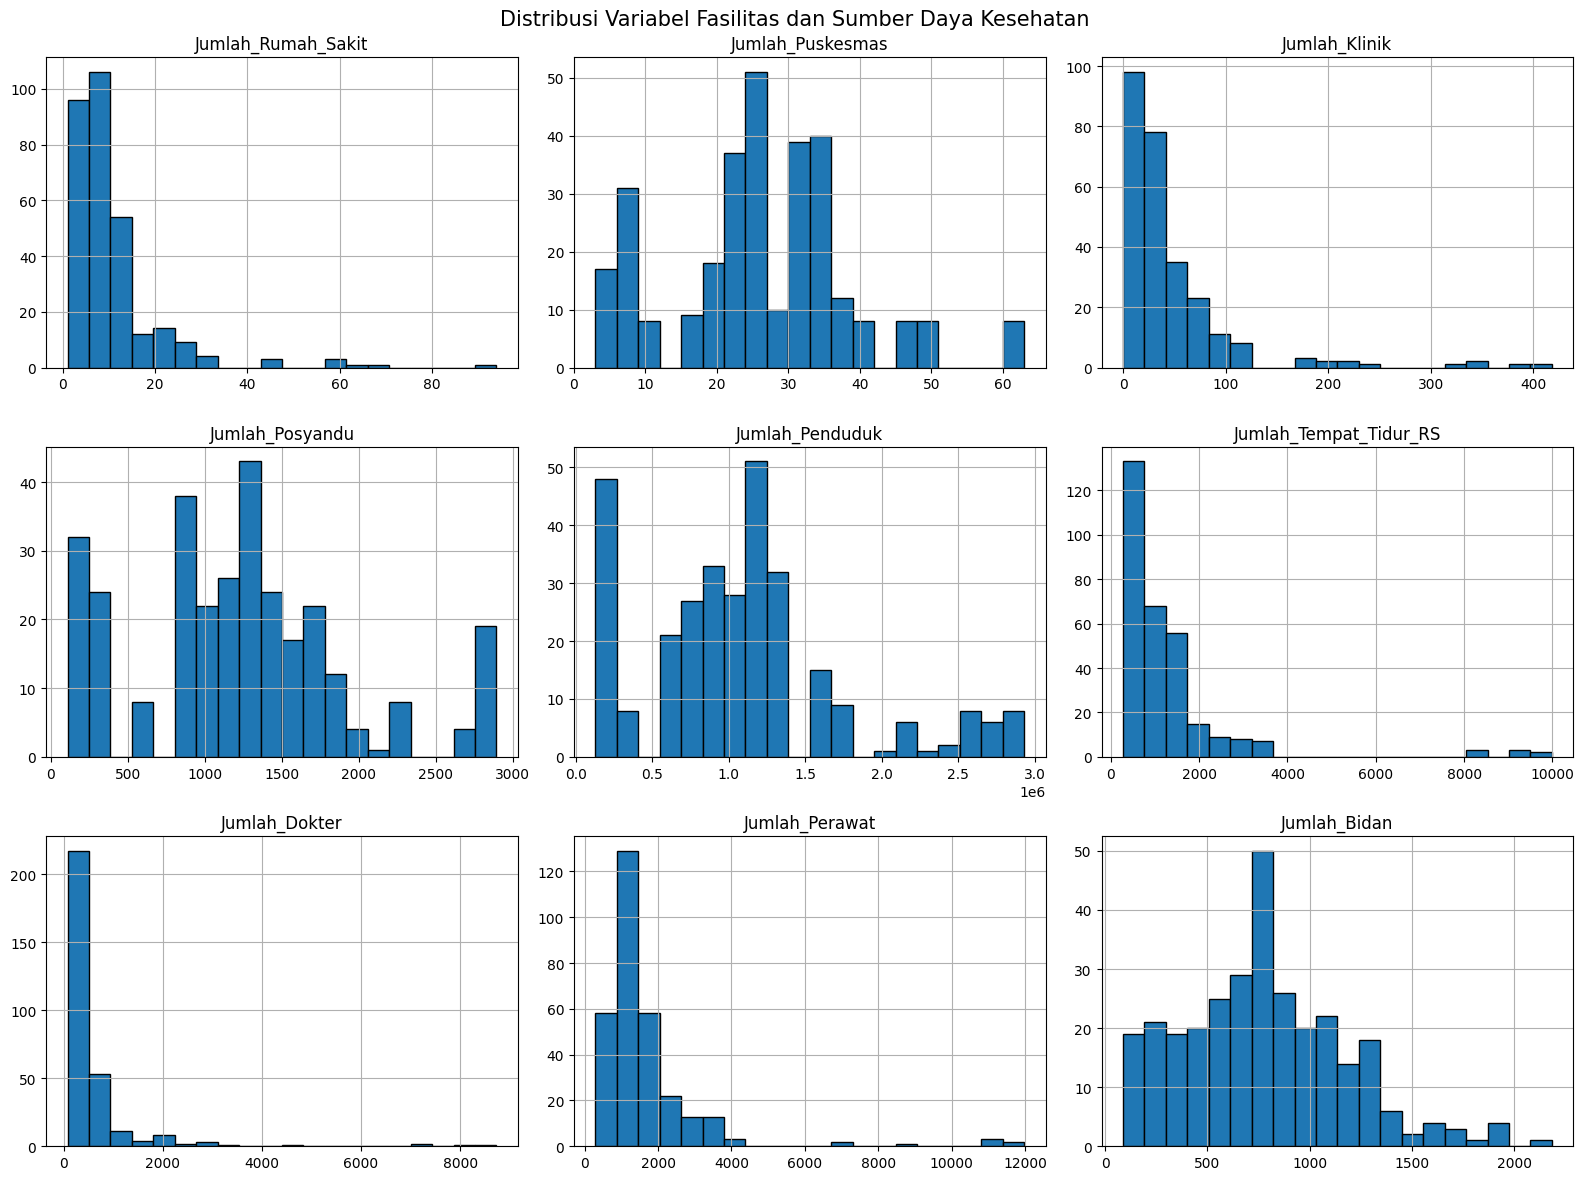

In [112]:
variabel_numerik = [
    "Jumlah_Rumah_Sakit",
    "Jumlah_Puskesmas",
    "Jumlah_Klinik",
    "Jumlah_Posyandu",
    "Jumlah_Penduduk",
    "Jumlah_Tempat_Tidur_RS",
    "Jumlah_Dokter",
    "Jumlah_Perawat",
    "Jumlah_Bidan"
]

dataset_utama[variabel_numerik].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribusi Variabel Fasilitas dan Sumber Daya Kesehatan",
    fontsize=15
)

plt.tight_layout()
plt.show()

### 5.2 Feature Engineering

Feature engineering dilakukan untuk membentuk indikator yang dapat menggambarkan ketersediaan fasilitas dan tenaga kesehatan dibandingkan dengan jumlah penduduk. Indikator dibentuk dalam bentuk rasio agar perbedaan jumlah penduduk antarwilayah dapat diperhitungkan.

Indikator yang digunakan terdiri atas rasio rumah sakit, tempat tidur rumah sakit, Puskesmas, Posyandu, dokter, perawat, dan bidan. Indikator klinik tidak digunakan dalam perhitungan indeks utama karena data tahun 2018 tidak tersedia pada seluruh kabupaten/kota.

Setiap rasio menggunakan satuan pengali yang disesuaikan untuk mempermudah interpretasi. Satuan pengali tersebut merupakan skala penyajian rasio dan tidak seluruhnya menunjukkan standar kecukupan resmi.

In [113]:
# Membuat salinan dataset utama
dataset_indeks = dataset_utama.copy()

# Menghitung indikator rasio
dataset_indeks["Rasio_Rumah_Sakit"] = (
    dataset_indeks["Jumlah_Rumah_Sakit"]
    / dataset_indeks["Jumlah_Penduduk"] * 100000
)

dataset_indeks["Rasio_Tempat_Tidur"] = (
    dataset_indeks["Jumlah_Tempat_Tidur_RS"]
    / dataset_indeks["Jumlah_Penduduk"] * 1000
)

dataset_indeks["Rasio_Puskesmas"] = (
    dataset_indeks["Jumlah_Puskesmas"]
    / dataset_indeks["Jumlah_Penduduk"] * 30000
)

dataset_indeks["Rasio_Posyandu"] = (
    dataset_indeks["Jumlah_Posyandu"]
    / dataset_indeks["Jumlah_Penduduk"] * 1000
)

dataset_indeks["Rasio_Dokter"] = (
    dataset_indeks["Jumlah_Dokter"]
    / dataset_indeks["Jumlah_Penduduk"] * 100000
)

dataset_indeks["Rasio_Perawat"] = (
    dataset_indeks["Jumlah_Perawat"]
    / dataset_indeks["Jumlah_Penduduk"] * 100000
)

dataset_indeks["Rasio_Bidan"] = (
    dataset_indeks["Jumlah_Bidan"]
    / dataset_indeks["Jumlah_Penduduk"] * 100000
)

# Daftar indikator
kolom_rasio = [
    "Rasio_Rumah_Sakit",
    "Rasio_Tempat_Tidur",
    "Rasio_Puskesmas",
    "Rasio_Posyandu",
    "Rasio_Dokter",
    "Rasio_Perawat",
    "Rasio_Bidan"
]

# Menampilkan hasil
display(
    dataset_indeks[
        ["Kabupaten_Kota", "Tahun"] + kolom_rasio
    ].head(10)
)

,Kabupaten_Kota,Tahun,Rasio_Rumah_Sakit,Rasio_Tempat_Tidur,Rasio_Puskesmas,Rasio_Posyandu,Rasio_Dokter,Rasio_Perawat,Rasio_Bidan
0,Kab. Bangkalan,2018,0.51,0.43,0.67,1.10,21.35,92.85,91.83
1,Kab. Bangkalan,2019,0.41,0.47,0.67,1.14,27.66,105.37,112.46
2,Kab. Bangkalan,2020,0.66,0.49,0.62,1.07,10.37,94.96,93.64
3,Kab. Bangkalan,2021,0.65,0.49,0.62,1.07,24.91,119.34,99.37
4,Kab. Bangkalan,2022,0.37,0.52,0.61,1.05,18.22,109.79,98.20
5,Kab. Bangkalan,2023,0.37,0.53,0.60,1.05,23.91,107.71,97.09
6,Kab. Bangkalan,2024,0.73,0.57,0.60,1.01,24.94,107.94,97.05
7,Kab. Bangkalan,2025,0.72,0.57,0.59,1.04,22.10,117.08,98.84
8,Kab. Banyuwangi,2018,0.87,0.82,0.84,1.43,33.35,83.85,59.19
9,Kab. Banyuwangi,2019,0.74,0.84,0.84,1.42,57.99,98.08,56.88


In [114]:
# Pemeriksaan kondisi indikator rasio
print("JUMLAH DATA:", len(dataset_indeks))

print("\nMISSING VALUE:")
display(dataset_indeks[kolom_rasio].isnull().sum())

print("\nINFINITE VALUE:")
display(
    np.isinf(dataset_indeks[kolom_rasio]).sum()
)

print("\nNILAI MINIMUM:")
display(dataset_indeks[kolom_rasio].min())

print("\nNILAI MAKSIMUM:")
display(dataset_indeks[kolom_rasio].max())

print("\nSTATISTIK DESKRIPTIF:")
display(dataset_indeks[kolom_rasio].describe().T)

JUMLAH DATA: 304

MISSING VALUE:


Rasio_Rumah_Sakit     0
Rasio_Tempat_Tidur    0
Rasio_Puskesmas       0
Rasio_Posyandu        0
Rasio_Dokter          0
Rasio_Perawat         0
Rasio_Bidan           0
dtype: int64


INFINITE VALUE:


Rasio_Rumah_Sakit     0
Rasio_Tempat_Tidur    0
Rasio_Puskesmas       0
Rasio_Posyandu        0
Rasio_Dokter          0
Rasio_Perawat         0
Rasio_Bidan           0
dtype: int64


NILAI MINIMUM:


Rasio_Rumah_Sakit     0.14
Rasio_Tempat_Tidur    0.28
Rasio_Puskesmas       0.35
Rasio_Posyandu        0.69
Rasio_Dokter          7.83
Rasio_Perawat        48.26
Rasio_Bidan          22.11
dtype: float64


NILAI MAKSIMUM:


Rasio_Rumah_Sakit      7.85
Rasio_Tempat_Tidur     7.23
Rasio_Puskesmas        1.40
Rasio_Posyandu         1.53
Rasio_Dokter         378.62
Rasio_Perawat        747.72
Rasio_Bidan          186.94
dtype: float64


STATISTIK DESKRIPTIF:


,count,mean,std,min,25%,50%,75%,max
Rasio_Rumah_Sakit,304.00,1.26,1.22,0.14,0.51,0.80,1.38,7.85
Rasio_Tempat_Tidur,304.00,1.53,1.49,0.28,0.67,0.87,1.49,7.23
Rasio_Puskesmas,304.00,0.78,0.20,0.35,0.65,0.76,0.89,1.40
Rasio_Posyandu,304.00,1.17,0.17,0.69,1.10,1.17,1.29,1.53
Rasio_Dokter,304.00,68.36,76.07,7.83,26.26,38.94,67.27,378.62
Rasio_Perawat,304.00,193.52,147.12,48.26,111.73,136.33,195.17,747.72
Rasio_Bidan,304.00,83.07,31.13,22.11,63.45,76.48,96.26,186.94
